# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# Soporte (S0–S6)

Esta sección agrupa, **fuera de los experimentos**, todo lo que los tres experimentos comparten: los `import`, la semilla única, las funciones de lógica y sus comprobaciones. **No es un experimento**: sus celdas no siguen la regla de tres celdas «predicción → implementación → interpretación», que sí rige para E1, E2 y E3.

## Cómo está organizado

| Celda | Contenido |
|---|---|
| **S1** | Imports del stack fijado, semilla única `SEED`, límite `MAX_CONFIGS`, orden y etiquetas de los modelos |
| **S2** | Datos y particiones: `make_splits`, `split_summary`, `sample_examples` |
| **S3** | Fábricas de modelos: `build_classifier`, `build_regressor` |
| **S4** | Protocolo: `fit_capturing_warnings`, `classification_metrics`, `regression_metrics`, `score_classifier`, `score_regressor`, `train_and_score`, `select_config`, `FrozenModel`/`freeze`, `evaluate_once`, `alpha_sweep`, `pick_best_alpha` |
| **S5** | Análisis: `make_table`, `format_config`, `format_warnings`, `simplicity_score`, `indistinguishable_cls`, `indistinguishable_reg`, `rank_models`, `never_predicted_classes`, `is_degenerate_cls`, `is_degenerate_reg`, `top_abs_errors`, `pick_two_errors`, `result_digest` |
| **S6** | Un `assert` como mínimo por cada función de S2–S5, con datos sintéticos (sin pytest) |

## Reglas que se cumplen en todo el notebook

- Las funciones **devuelven valores**: no imprimen, no muestran tablas y no dibujan. Mostrar y graficar ocurre solo en las celdas de implementación de cada experimento.
- Una **configuración** es una combinación distinta de hiperparámetros (incluidos `max_iter` y `solver`); la semilla no cuenta y se inyecta desde `SEED`.
- **Congelar** es fijar la configuración y el modelo ajustado solo con entrenamiento; no se reentrena con validación y la partición de prueba se evalúa una sola vez por modelo.
- Los avisos de scikit-learn se **capturan y se muestran en tablas**; nunca se silencian.
- Solo cuenta como válida la ejecución completa **desde cero** (*Restart & Run All*).

In [13]:
# [S1] Imports, single seed and protocol constants
import hashlib
import warnings
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.datasets import load_diabetes, load_iris
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Single source of randomness: every random_state and every RNG below receives this value.
SEED = 42

# Maximum number of configurations per model, the initial one included.
# The alpha sweep of Ridge and Lasso is the only declared exception.
MAX_CONFIGS = 4

# Model order is fixed by the statement (classification: block 2, regression: block 3).
CLF_KEYS = ["gaussian_nb", "logistic_regression", "linear_svm", "decision_tree",
            "random_forest", "gradient_boosting", "mlp"]
CLF_LABELS = {
    "gaussian_nb": "Gaussian Naive Bayes",
    "logistic_regression": "Regresión logística",
    "linear_svm": "SVM lineal",
    "decision_tree": "Árbol de decisión",
    "random_forest": "Random Forest",
    "gradient_boosting": "Gradient Boosting",
    "mlp": "MLP",
}
REG_KEYS = ["linear_regression", "ridge", "lasso", "knn", "decision_tree",
            "random_forest", "gradient_boosting", "mlp"]
REG_LABELS = {
    "linear_regression": "Regresión lineal",
    "ridge": "Ridge",
    "lasso": "Lasso",
    "knn": "kNN",
    "decision_tree": "Árbol de regresión",
    "random_forest": "Random Forest",
    "gradient_boosting": "Gradient Boosting",
    "mlp": "MLP",
}
PARTITION_LABELS = {"train": "entrenamiento", "val": "validación", "test": "prueba"}

# Table display options (presentation only).
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)

In [14]:
# [S2] Data and partition logic (returns values; nothing is shown or drawn here)
def make_splits(y, stratify, seed):
    """Return sorted index arrays for a 60/20/20 train/val/test partition (two chained splits)."""
    y = np.asarray(y)
    idx = np.arange(len(y))
    rest, test = train_test_split(idx, test_size=0.20, random_state=seed,
                                  stratify=y if stratify else None)
    train, val = train_test_split(rest, test_size=0.25, random_state=seed,
                                  stratify=y[rest] if stratify else None)
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


def split_summary(y, splits, class_names):
    """Size and per-class counts of each partition, as a DataFrame with Spanish headers."""
    y = np.asarray(y)
    rows = []
    for name in ("train", "val", "test"):
        part = y[splits[name]]
        row = {"Partición": PARTITION_LABELS[name], "Tamaño": int(len(part))}
        for code, label in enumerate(class_names):
            row[label] = int(np.sum(part == code))
        rows.append(row)
    return pd.DataFrame(rows)


def sample_examples(y, n, seed):
    """Pick n distinct indices at random, guaranteeing that every class appears at least once."""
    y = np.asarray(y)
    classes = np.unique(y)
    if n < len(classes):
        raise ValueError("n must be at least the number of classes")
    rng = np.random.default_rng(seed)
    chosen = [int(rng.choice(np.flatnonzero(y == c))) for c in classes]
    remaining = np.setdiff1d(np.arange(len(y)), chosen)
    extra = rng.choice(remaining, size=n - len(chosen), replace=False)
    return np.sort(np.concatenate([np.array(chosen, dtype=int), extra.astype(int)]))

In [15]:
# [S3] Model factories (the seed is injected here and is never part of a config)
def build_classifier(key, config, seed, scaled):
    """Return an unfitted Pipeline; the scaler step exists only when scaled is True."""
    if "random_state" in config:
        raise ValueError("the seed is injected by the factory, not written in the config")
    if key == "gaussian_nb":
        model = GaussianNB(**config)
    elif key == "logistic_regression":
        model = LogisticRegression(**config, random_state=seed)
    elif key == "linear_svm":
        model = LinearSVC(**config, random_state=seed)
    elif key == "decision_tree":
        model = DecisionTreeClassifier(**config, random_state=seed)
    elif key == "random_forest":
        model = RandomForestClassifier(**config, random_state=seed)
    elif key == "gradient_boosting":
        model = GradientBoostingClassifier(**config, random_state=seed)
    elif key == "mlp":
        model = MLPClassifier(**config, random_state=seed)
    else:
        raise ValueError(f"unknown classifier key: {key}")
    steps = [("scaler", StandardScaler())] if scaled else []
    return Pipeline(steps + [("model", model)])


# Regressors that need standardized inputs (distance-based, penalized or gradient-trained).
SCALED_REGRESSORS = ("ridge", "lasso", "knn", "mlp")


def build_regressor(key, config, seed):
    """Return an unfitted regressor; only the MLP wraps the target in a train-fitted scaler."""
    if "random_state" in config:
        raise ValueError("the seed is injected by the factory, not written in the config")
    if key == "linear_regression":
        model = LinearRegression(**config)
    elif key == "ridge":
        model = Ridge(**config, random_state=seed)
    elif key == "lasso":
        model = Lasso(**config, random_state=seed)
    elif key == "knn":
        model = KNeighborsRegressor(**config)
    elif key == "decision_tree":
        model = DecisionTreeRegressor(**config, random_state=seed)
    elif key == "random_forest":
        model = RandomForestRegressor(**config, random_state=seed)
    elif key == "gradient_boosting":
        model = GradientBoostingRegressor(**config, random_state=seed)
    elif key == "mlp":
        model = MLPRegressor(**config, random_state=seed)
    else:
        raise ValueError(f"unknown regressor key: {key}")
    steps = [("scaler", StandardScaler())] if key in SCALED_REGRESSORS else []
    pipe = Pipeline(steps + [("model", model)])
    if key == "mlp":
        # The target is standardized with train statistics and inverted before any metric.
        return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())
    return pipe

In [16]:
# [S4] Protocol logic: fit, score, select, freeze, single test evaluation and alpha sweep
def fit_capturing_warnings(est, X, y):
    """Fit est and return (est, warnings). Every warning is kept; none is filtered out."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        est.fit(X, y)
    return est, [{"category": w.category.__name__, "message": str(w.message)} for w in caught]


def classification_metrics(y_true, y_pred):
    """Accuracy, macro F1 and micro F1 of a prediction vector."""
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro")),
        "f1_micro": float(f1_score(y_true, y_pred, average="micro")),
    }


def regression_metrics(y_true, y_pred):
    """MAE, RMSE and R2 of a prediction vector (original target scale)."""
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(root_mean_squared_error(y_true, y_pred)),
        "r2": float(r2_score(y_true, y_pred)),
    }


def score_classifier(est, X_eval, y_eval):
    """Predict with a fitted estimator; return (y_pred, metrics, warnings)."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        y_pred = est.predict(X_eval)
        metrics = classification_metrics(y_eval, y_pred)
    return y_pred, metrics, [{"category": w.category.__name__, "message": str(w.message)}
                             for w in caught]


def score_regressor(est, X_eval, y_eval):
    """Predict with a fitted estimator; return (y_pred, metrics, warnings)."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        y_pred = est.predict(X_eval)
        metrics = regression_metrics(y_eval, y_pred)
    return y_pred, metrics, [{"category": w.category.__name__, "message": str(w.message)}
                             for w in caught]


def train_and_score(est, X_fit, y_fit, X_eval, y_eval, scorer):
    """Fit on the fitting data only, score on the evaluation data, keep all warnings."""
    est, fit_warnings = fit_capturing_warnings(est, X_fit, y_fit)
    y_pred, metrics, eval_warnings = scorer(est, X_eval, y_eval)
    return {"estimator": est, "y_pred": y_pred, **metrics,
            "warnings_fit": fit_warnings, "warnings_eval": eval_warnings}


def select_config(records, primary, support, higher_is_better):
    """Pick the best record: primary metric, then support metric, then the one tried first."""
    sign = 1.0 if higher_is_better else -1.0
    return max(records, key=lambda r: (round(sign * r[primary], 12),
                                       round(sign * r[support], 12),
                                       -r["order"]))


class FrozenModel(NamedTuple):
    """Immutable pair (configuration, estimator fitted on train only)."""
    model: str
    config: dict
    estimator: object
    n_configs: int


def freeze(key, record, n_configs):
    """Freeze a chosen record without refitting: the estimator was fitted on train only."""
    return FrozenModel(model=key, config=dict(record["config"]),
                       estimator=record["estimator"], n_configs=int(n_configs))


def evaluate_once(frozen, X_eval, y_eval, ledger, scorer):
    """Score a frozen model on the held-out partition; fails if it was already evaluated."""
    if frozen.model in ledger:
        raise RuntimeError(f"{frozen.model} was already evaluated on the held-out partition")
    ledger.add(frozen.model)
    y_pred, metrics, caught = scorer(frozen.estimator, X_eval, y_eval)
    return {"y_pred": y_pred, **metrics, "warnings_eval": caught}


def alpha_sweep(key, base_config, alphas, data, seed):
    """One fitted pipeline per alpha (fit on data['X_fit']), scored on fit and eval data."""
    rows = []
    for alpha in alphas:
        config = {**base_config, "alpha": float(alpha)}
        est = build_regressor(key, config, seed)
        est, fit_warnings = fit_capturing_warnings(est, data["X_fit"], data["y_fit"])
        _, m_fit, _ = score_regressor(est, data["X_fit"], data["y_fit"])
        _, m_eval, eval_warnings = score_regressor(est, data["X_eval"], data["y_eval"])
        coef = est.named_steps["model"].coef_
        rows.append({
            "model": key, "alpha": float(alpha), "config": config,
            "l2_norm": float(np.linalg.norm(coef)), "n_zero": int(np.sum(coef == 0.0)),
            "rmse_train": m_fit["rmse"], "rmse_val": m_eval["rmse"], "mae_val": m_eval["mae"],
            "coef": np.array(coef, copy=True),
            "warnings_fit": fit_warnings, "warnings_eval": eval_warnings, "estimator": est,
        })
    return rows


def pick_best_alpha(rows):
    """Lowest validation RMSE; an exact tie goes to the smaller alpha. Flags the grid border."""
    best = min(rows, key=lambda r: (round(r["rmse_val"], 12), r["alpha"]))
    alphas = [r["alpha"] for r in rows]
    return {"alpha": best["alpha"],
            "at_border": best["alpha"] in (min(alphas), max(alphas)),
            "row": best}

In [17]:
# [S5] Analysis logic: comparisons, degenerate results, errors and fingerprints
def make_table(rows, columns):
    """DataFrame with exactly the given columns and a 1-based index (presentation is up to the caller)."""
    table = pd.DataFrame(rows, columns=columns)
    table.index = pd.RangeIndex(1, len(table) + 1)
    return table


def format_config(config):
    """Text with only the hyperparameters explicitly written in the configuration."""
    if not config:
        return "sin hiperparámetros fijados"
    parts = []
    for name, value in config.items():
        shown = float(f"{value:.6g}") if isinstance(value, float) else value
        parts.append(f"{name}={shown}")
    return ", ".join(parts)


def format_warnings(warns):
    """Compact text of captured warnings (category and count), or a dash when there are none."""
    if not warns:
        return "—"
    counts = {}
    for item in warns:
        counts[item["category"]] = counts.get(item["category"], 0) + 1
    return "; ".join(f"{name} ×{count}" for name, count in counts.items())


def simplicity_score(frozen):
    """Explicitly fixed hyperparameters plus configurations tried (lower = simpler to program)."""
    return len(frozen.config) + frozen.n_configs


def indistinguishable_cls(errors, best, tol=1):
    """Models (other than best) with at most tol more test errors than the best one."""
    return [m for m, e in errors.items() if m != best and e - errors[best] <= tol]


def indistinguishable_reg(rmse, best, tol=0.05):
    """Models (other than best) within tol (relative to the best RMSE) of the best RMSE."""
    return [m for m, v in rmse.items()
            if m != best and (v - rmse[best]) / rmse[best] <= tol + 1e-12]


def rank_models(values, higher_is_better):
    """Competition ranking (1 = best); ties share the same position."""
    sign = -1.0 if higher_is_better else 1.0
    keyed = {m: round(sign * float(v), 12) for m, v in values.items()}
    return {m: 1 + sum(1 for other in keyed.values() if other < keyed[m]) for m in keyed}


def never_predicted_classes(y_pred, classes):
    """Classes (in the given order) that the prediction vector never contains."""
    seen = set(np.asarray(y_pred).tolist())
    return [int(c) for c in classes if int(c) not in seen]


def is_degenerate_cls(y_pred, classes):
    """True when the classifier never predicts at least one class."""
    return len(never_predicted_classes(y_pred, classes)) > 0


def is_degenerate_reg(est):
    """True when a linear model has every coefficient exactly zero (a constant predictor)."""
    model = est.named_steps["model"] if hasattr(est, "named_steps") else None
    coef = getattr(model, "coef_", None)
    return coef is not None and bool(np.all(np.asarray(coef) == 0.0))


def top_abs_errors(y_true, y_pred, k=2):
    """Positions of the k largest absolute errors (ties go to the smaller position)."""
    err = np.abs(np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float))
    order = sorted(range(len(err)), key=lambda i: (-err[i], i))
    return np.array(order[:k], dtype=int)


def pick_two_errors(pred_main, pred_extra, y_main, y_extra, model_order, idx_main, idx_extra):
    """Up to two distinct misclassified instances, taken from the main (held-out) partition
    first and completed, if needed, from the extra (validation) partition with a label."""
    chosen = []
    wrong_main = {m: np.asarray(pred_main[m]) != np.asarray(y_main) for m in model_order}
    fails = np.sum([wrong_main[m] for m in model_order], axis=0)
    candidates = sorted((i for i in range(len(y_main)) if fails[i] > 0),
                        key=lambda i: (-int(fails[i]), int(idx_main[i])))
    for i in candidates[:2]:
        first = next(m for m in model_order if wrong_main[m][i])
        chosen.append({"index": int(idx_main[i]), "position": int(i), "partition": "prueba",
                       "model": first, "also_failed": int(fails[i]) - 1, "note": ""})
    if len(chosen) < 2:
        wrong_extra = {m: np.asarray(pred_extra[m]) != np.asarray(y_extra) for m in model_order}
        fails_extra = np.sum([wrong_extra[m] for m in model_order], axis=0)
        by_errors = sorted(model_order,
                           key=lambda m: (-int(wrong_extra[m].sum()), model_order.index(m)))
        seen = {c["index"] for c in chosen}
        for m in by_errors:
            for i in sorted(np.flatnonzero(wrong_extra[m]), key=lambda j: int(idx_extra[j])):
                if len(chosen) >= 2:
                    break
                if int(idx_extra[i]) in seen:
                    continue
                seen.add(int(idx_extra[i]))
                chosen.append({"index": int(idx_extra[i]), "position": int(i),
                               "partition": "validación", "model": m,
                               "also_failed": int(fails_extra[i]) - 1,
                               "note": "posible sesgo optimista: la validación se usó para decidir"})
    return chosen


def result_digest(*arrays):
    """Short SHA-256 of the arrays rounded to 6 decimals (shape included)."""
    digest = hashlib.sha256()
    for array in arrays:
        values = np.asarray(array, dtype=float)
        digest.update(str(values.shape).encode())
        digest.update((np.round(values, 6) + 0.0).tobytes())
    return digest.hexdigest()[:16]

In [18]:
# [S6] Checks of every logic function of S2-S5 (plain asserts, synthetic data only)

# ---- S2: make_splits, split_summary, sample_examples ----
_y3 = np.array([0] * 50 + [1] * 50 + [2] * 50)
_sp = make_splits(_y3, stratify=True, seed=SEED)
assert [len(_sp[k]) for k in ("train", "val", "test")] == [90, 30, 30], "make_splits: sizes must be 90/30/30"
_union = np.concatenate([_sp["train"], _sp["val"], _sp["test"]])
assert sorted(_union.tolist()) == list(range(150)), "make_splits: partitions must be disjoint and complete"
for _part, _per_class in (("train", 30), ("val", 10), ("test", 10)):
    assert np.bincount(_y3[_sp[_part]]).tolist() == [_per_class] * 3, "make_splits: stratification broken"
_sp_again = make_splits(_y3, stratify=True, seed=SEED)
assert all(np.array_equal(_sp[k], _sp_again[k]) for k in _sp), "make_splits: same seed, same indices"
_sp_other = make_splits(_y3, stratify=True, seed=SEED + 1)
assert not np.array_equal(_sp["test"], _sp_other["test"]), "make_splits: another seed must change the split"
_sp_reg = make_splits(np.zeros(442), stratify=False, seed=SEED)
assert [len(_sp_reg[k]) for k in ("train", "val", "test")] == [264, 89, 89], "make_splits: 442 rows -> 264/89/89"

_summary = split_summary(_y3, _sp, ["a", "b", "c"])
assert _summary["Tamaño"].tolist() == [90, 30, 30], "split_summary: sizes"
assert _summary[["a", "b", "c"]].to_numpy().tolist() == [[30, 30, 30], [10, 10, 10], [10, 10, 10]], \
    "split_summary: per-class counts"

_ex = sample_examples(_y3, 5, SEED)
assert len(set(_ex.tolist())) == 5, "sample_examples: indices must be distinct"
assert set(_y3[_ex].tolist()) == {0, 1, 2}, "sample_examples: all classes must appear"
assert np.array_equal(_ex, sample_examples(_y3, 5, SEED)), "sample_examples: must be deterministic"

# ---- S3: build_classifier, build_regressor ----
assert len(CLF_KEYS) == 7 and len(REG_KEYS) == 8, "model lists must have 7 classifiers and 8 regressors"
for _scaled in (True, False):
    for _key in CLF_KEYS:
        _est = build_classifier(_key, {}, SEED, scaled=_scaled)
        _step_names = [name for name, _ in _est.steps]
        assert _step_names == (["scaler", "model"] if _scaled else ["model"]), "build_classifier: scaler step"
        if _scaled:
            assert isinstance(_est.named_steps["scaler"], StandardScaler), "build_classifier: StandardScaler"
        _params = _est.named_steps["model"].get_params()
        assert _params.get("random_state", SEED) == SEED, "build_classifier: random_state must be SEED"
assert isinstance(build_classifier("linear_svm", {}, SEED, True).named_steps["model"], LinearSVC)
assert build_classifier("mlp", {}, SEED, True).named_steps["model"].early_stopping is False, \
    "MLP must not use an internal validation split"
assert build_classifier("gradient_boosting", {}, SEED, True).named_steps["model"].n_iter_no_change is None, \
    "Gradient Boosting must not use an internal validation split"

for _key in REG_KEYS:
    _est = build_regressor(_key, {}, SEED)
    _core = _est.regressor if isinstance(_est, TransformedTargetRegressor) else _est
    assert ("scaler" in _core.named_steps) == (_key in ("ridge", "lasso", "knn", "mlp")), "build_regressor: scaler"
    assert _core.named_steps["model"].get_params().get("random_state", SEED) == SEED, "build_regressor: seed"
assert [isinstance(build_regressor(k, {}, SEED), TransformedTargetRegressor) for k in REG_KEYS] == \
    [k == "mlp" for k in REG_KEYS], "only the MLP wraps the target"
_mlp_core = build_regressor("mlp", {}, SEED).regressor.named_steps["model"]
assert _mlp_core.early_stopping is False, "MLP regressor must not use an internal validation split"
assert build_regressor("gradient_boosting", {}, SEED).named_steps["model"].n_iter_no_change is None

# ---- S4: fit_capturing_warnings, metrics, score_*, train_and_score ----
_rng = np.random.default_rng(SEED)
_Xc = _rng.normal(size=(90, 4))
_yc = np.digitize(_Xc[:, 0] + 0.3 * _Xc[:, 1], [-0.5, 0.5])
_lr, _lr_warnings = fit_capturing_warnings(LogisticRegression(max_iter=1), _Xc, _yc)
assert hasattr(_lr, "coef_"), "fit_capturing_warnings: estimator must come back fitted"
assert any(w["category"] == "ConvergenceWarning" for w in _lr_warnings), "ConvergenceWarning must be captured"

_m = classification_metrics([0, 0, 1, 1, 2, 2], [0, 0, 1, 2, 2, 2])
assert abs(_m["f1_macro"] - (1 + 2 / 3 + 4 / 5) / 3) < 1e-12, "classification_metrics: macro F1"
assert abs(_m["f1_micro"] - 5 / 6) < 1e-12 and abs(_m["accuracy"] - 5 / 6) < 1e-12, "micro F1 equals accuracy"
_r = regression_metrics([1, 2, 3], [1, 2, 5])
assert abs(_r["mae"] - 2 / 3) < 1e-12 and abs(_r["rmse"] - np.sqrt(4 / 3)) < 1e-12 and abs(_r["r2"] + 1) < 1e-12, \
    "regression_metrics: MAE, RMSE and R2 of a known case"

_pred, _met, _score_warnings = score_classifier(_lr, _Xc, _yc)
assert _met == classification_metrics(_yc, _pred) and isinstance(_score_warnings, list), "score_classifier"
_Xr = _rng.normal(size=(60, 3))
_yr = _Xr @ np.array([2.0, -1.0, 0.5]) + 10
_lin, _ = fit_capturing_warnings(build_regressor("linear_regression", {}, SEED), _Xr, _yr)
_pred_r, _met_r, _ = score_regressor(_lin, _Xr, _yr)
assert _met_r == regression_metrics(_yr, _pred_r) and _met_r["r2"] > 0.999, "score_regressor"

_res = train_and_score(build_classifier("gaussian_nb", {}, SEED, True), _Xc, _yc, _Xc, _yc, score_classifier)
assert set(_res) >= {"estimator", "y_pred", "accuracy", "f1_macro", "warnings_fit", "warnings_eval"}, \
    "train_and_score: result keys"

# ---- S4: select_config ----
_recs = [{"order": 0, "f1": 0.9, "acc": 0.8}, {"order": 1, "f1": 0.9, "acc": 0.9}, {"order": 2, "f1": 0.8, "acc": 1.0}]
assert select_config(_recs, "f1", "acc", True)["order"] == 1, "select_config: tie goes to the support metric"
_recs_tie = [{"order": 0, "f1": 0.9, "acc": 0.9}, {"order": 1, "f1": 0.9, "acc": 0.9}]
assert select_config(_recs_tie, "f1", "acc", True)["order"] == 0, "select_config: persistent tie, first tried"
_recs_reg = [{"order": 0, "rmse": 5.0, "mae": 4.0}, {"order": 1, "rmse": 3.0, "mae": 4.5},
             {"order": 2, "rmse": 3.0, "mae": 4.0}]
assert select_config(_recs_reg, "rmse", "mae", False)["order"] == 2, "select_config: lower is better"

# ---- S4: freeze, evaluate_once ----
_nb, _ = fit_capturing_warnings(build_classifier("gaussian_nb", {}, SEED, True), _Xc, _yc)
_frozen = freeze("gaussian_nb", {"order": 0, "config": {"var_smoothing": 1e-9}, "estimator": _nb}, 3)
assert _frozen.model == "gaussian_nb" and _frozen.n_configs == 3 and _frozen.estimator is _nb, "freeze fields"
try:
    _frozen.model = "other"
    raise AssertionError("FrozenModel must be immutable")
except AttributeError:
    pass
_ledger = set()
_first = evaluate_once(_frozen, _Xc, _yc, _ledger, score_classifier)
assert _ledger == {"gaussian_nb"} and np.array_equal(_first["y_pred"], _nb.predict(_Xc)), "evaluate_once"
try:
    evaluate_once(_frozen, _Xc, _yc, _ledger, score_classifier)
    raise AssertionError("a second evaluation of the same model must fail")
except RuntimeError:
    pass

# ---- S4: alpha_sweep, pick_best_alpha ----
_Xa = _rng.normal(size=(120, 5))
_ya = _Xa @ np.array([3.0, -2.0, 0.0, 0.0, 1.0]) + _rng.normal(scale=0.5, size=120)
_data = {"X_fit": _Xa[:80], "y_fit": _ya[:80], "X_eval": _Xa[80:], "y_eval": _ya[80:]}
_ridge_rows = alpha_sweep("ridge", {}, np.logspace(-2, 2, 6), _data, SEED)
_norms = [row["l2_norm"] for row in _ridge_rows]
assert all(_norms[i] >= _norms[i + 1] for i in range(len(_norms) - 1)), "Ridge L2 norm must not grow with alpha"
_Xs = StandardScaler().fit_transform(_data["X_fit"])
_alpha_max = np.max(np.abs(_Xs.T @ (_data["y_fit"] - _data["y_fit"].mean()))) / len(_Xs)
_lasso_rows = alpha_sweep("lasso", {"max_iter": 10000}, [1e-3, _alpha_max * 1.01], _data, SEED)
assert _lasso_rows[-1]["n_zero"] == 5, "Lasso above alpha_max must zero every coefficient"
assert _lasso_rows[0]["n_zero"] < 5, "Lasso with a tiny alpha must keep coefficients"

_grid_rows = [{"alpha": 0.1, "rmse_val": 5.0}, {"alpha": 1.0, "rmse_val": 3.0},
              {"alpha": 10.0, "rmse_val": 3.0}, {"alpha": 100.0, "rmse_val": 9.0}]
_best = pick_best_alpha(_grid_rows)
assert _best["alpha"] == 1.0 and _best["at_border"] is False, "pick_best_alpha: exact tie goes to the smaller alpha"
_border = pick_best_alpha([{"alpha": 0.1, "rmse_val": 1.0}, {"alpha": 1.0, "rmse_val": 2.0}])
assert _border["alpha"] == 0.1 and _border["at_border"] is True, "pick_best_alpha: border must be flagged"

# ---- S5: tables, formatting, simplicity, ranking ----
_tab = make_table([[1, 2], [3, 4]], ["a", "b"])
assert list(_tab.columns) == ["a", "b"] and list(_tab.index) == [1, 2], "make_table: columns and 1-based index"
assert format_config({"C": 1.0, "max_iter": 1000}) == "C=1.0, max_iter=1000", "format_config"
assert format_config({}) == "sin hiperparámetros fijados", "format_config: empty config"
assert format_warnings([]) == "—", "format_warnings: empty"
assert format_warnings([{"category": "ConvergenceWarning", "message": "x"}] * 2) == "ConvergenceWarning ×2"
assert simplicity_score(FrozenModel("m", {"a": 1, "b": 2}, None, 3)) == 5, "simplicity_score"
assert rank_models({"a": 0.9, "b": 0.9, "c": 0.8}, True) == {"a": 1, "b": 1, "c": 3}, "rank_models: ties"
assert rank_models({"a": 2.0, "b": 1.0}, False) == {"a": 2, "b": 1}, "rank_models: lower is better"

# ---- S5: indistinguishable_*, degenerate, top errors ----
assert indistinguishable_cls({"a": 2, "b": 3, "c": 4}, "a") == ["b"], "cls: 1 error apart included, 2 excluded"
assert indistinguishable_cls({"a": 2, "b": 1}, "a") == ["b"], "cls: fewer errors than the best is included"
assert indistinguishable_reg({"a": 100.0, "b": 105.0, "c": 105.01}, "a") == ["b"], "reg: exactly 5% included"
assert never_predicted_classes([0, 0, 1], [0, 1, 2]) == [2], "never_predicted_classes"
assert is_degenerate_cls([0, 0, 1], [0, 1, 2]) and not is_degenerate_cls([0, 1, 2], [0, 1, 2]), "is_degenerate_cls"
_zero, _ = fit_capturing_warnings(build_regressor("lasso", {"alpha": 1e6, "max_iter": 1000}, SEED), _Xa, _ya)
_ridge, _ = fit_capturing_warnings(build_regressor("ridge", {"alpha": 1.0}, SEED), _Xa, _ya)
assert is_degenerate_reg(_zero) and not is_degenerate_reg(_ridge), "is_degenerate_reg"
assert top_abs_errors([0, 0, 0, 0], [1, -3, 3, 0.5], k=2).tolist() == [1, 2], "top_abs_errors: ties, smaller position"

# ---- S5: pick_two_errors (three scenarios plus a validation-only case) ----
_order = ["m1", "m2", "m3"]
_yt = np.array([0, 1, 2, 0, 1, 2])
_it = np.array([10, 11, 12, 13, 14, 15])
_pt = {"m1": np.array([0, 2, 2, 0, 0, 2]), "m2": np.array([0, 2, 2, 0, 1, 2]), "m3": np.array([0, 1, 0, 0, 0, 2])}
_yv = np.array([0, 1, 2, 0])
_iv = np.array([20, 21, 22, 23])
_pv = {"m1": np.array([0, 2, 2, 0]), "m2": np.array([0, 1, 2, 0]), "m3": np.array([0, 2, 2, 1])}
_two = pick_two_errors(_pt, _pv, _yt, _yv, _order, _it, _iv)
assert [e["index"] for e in _two] == [11, 14] and all(e["partition"] == "prueba" for e in _two), \
    "pick_two_errors: test errors ordered by number of failing models"
assert _two[0]["model"] == "m1" and _two[0]["also_failed"] == 1, "pick_two_errors: first failing model and count"
_one_test = {"m1": np.array([0, 1, 2, 0, 1, 2]), "m2": np.array([0, 2, 2, 0, 1, 2]), "m3": _yt.copy()}
_mixed = pick_two_errors(_one_test, _pv, _yt, _yv, _order, _it, _iv)
assert [e["partition"] for e in _mixed] == ["prueba", "validación"], "pick_two_errors: test first, then validation"
assert _mixed[1]["model"] == "m3" and _mixed[1]["index"] == 21, \
    "pick_two_errors: validation error comes from the model with most validation errors"
assert "optimista" in _mixed[1]["note"], "pick_two_errors: optimistic-bias note"
_clean = {m: _yt.copy() for m in _order}
_clean_v = {m: _yv.copy() for m in _order}
assert pick_two_errors(_clean, _clean_v, _yt, _yv, _order, _it, _iv) == [], "pick_two_errors: no errors anywhere"
_val_only = pick_two_errors(_clean, _pv, _yt, _yv, _order, _it, _iv)
assert [e["index"] for e in _val_only] == [21, 23] and {e["model"] for e in _val_only} == {"m3"}, \
    "pick_two_errors: validation-only errors come from the model with most validation errors"

# ---- S5: result_digest ----
_fp = result_digest(np.array([0.5, 1.5]), np.array([[1.0, 2.0]]))
assert _fp == result_digest(np.array([0.5, 1.5]), np.array([[1.0, 2.0]])), "fingerprint: same input"
assert _fp != result_digest(np.array([0.5, 1.6]), np.array([[1.0, 2.0]])), "fingerprint: altered input"
assert _fp == result_digest(np.array([0.5 + 1e-9, 1.5]), np.array([[1.0, 2.0]])), "fingerprint: 6 decimals"

In [19]:
# [S7] Softmax and output scores of an MLP classifier (returns values; nothing is shown or drawn here)
def softmax(scores):
    """Numerically stable softmax over the last axis: the maximum is subtracted before the exponential."""
    z = np.asarray(scores, dtype=float)
    if z.size == 0:
        raise ValueError("scores must not be empty")
    if not np.all(np.isfinite(z)):
        raise ValueError("scores must be finite (nan and inf are not allowed)")
    exps = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return exps / np.sum(exps, axis=-1, keepdims=True)


def mlp_output_scores(pipeline, X):
    """Scores of the output layer (the values softmax receives) of a fitted Pipeline with an MLPClassifier.

    Only public attributes are used: the optional scaler of the pipeline, coefs_, intercepts_ and activation.
    """
    hidden_activations = {
        "relu": lambda a: np.maximum(a, 0.0),
        "tanh": np.tanh,
        "logistic": lambda a: 0.5 * (1.0 + np.tanh(0.5 * a)),  # equals 1 / (1 + e^-a) and cannot overflow
        "identity": lambda a: a,
    }
    mlp = pipeline.named_steps["model"]
    if mlp.activation not in hidden_activations:
        raise ValueError(f"unsupported hidden activation: {mlp.activation}")
    scaler = pipeline.named_steps.get("scaler")
    a = np.asarray(X, dtype=float)
    if scaler is not None:
        a = scaler.transform(a)
    for weights, bias in zip(mlp.coefs_[:-1], mlp.intercepts_[:-1]):
        a = hidden_activations[mlp.activation](a @ weights + bias)
    return a @ mlp.coefs_[-1] + mlp.intercepts_[-1]


# ---- S7: softmax ----
assert np.allclose(softmax([0.0, 0.0, 0.0]), [1 / 3, 1 / 3, 1 / 3], atol=1e-15, rtol=0), "softmax: equal scores"
_z7 = np.array([2.0, -1.0, 0.5, 3.0])
_p7 = softmax(_z7)
assert abs(_p7.sum() - 1.0) <= 1e-12, "softmax: the outputs must sum 1"
assert np.all((_p7 > 0.0) & (_p7 < 1.0)), "softmax: every probability must lie in (0, 1)"
assert np.array_equal(np.argsort(_p7), np.argsort(_z7)), "softmax: the order of the scores is kept"
assert np.allclose(softmax(_z7 + 123.456), _p7, atol=1e-12, rtol=0), "softmax: adding a constant changes nothing"
_rows7 = softmax(np.array([[2.0, 1.0, 0.1], [0.0, 0.0, 0.0]]))
assert _rows7.shape == (2, 3) and np.allclose(_rows7.sum(axis=1), 1.0, atol=1e-12, rtol=0), "softmax: row-wise"
_big7, _small7 = softmax([1000.0, 1001.0, 1002.0]), softmax([-1000.0, -1001.0, -1002.0])
assert np.all(np.isfinite(_big7)) and np.all(np.isfinite(_small7)), "softmax: huge scores must stay finite"
assert np.allclose(_big7, softmax([0.0, 1.0, 2.0]), atol=1e-15, rtol=0), "softmax: large positive scores"
assert np.allclose(_small7, softmax([0.0, -1.0, -2.0]), atol=1e-15, rtol=0), "softmax: large negative scores"
for _bad7 in ([1.0, np.nan, 0.0], [np.inf, 0.0, 0.0], [0.0, -np.inf, 1.0]):
    try:
        softmax(_bad7)
        raise AssertionError("softmax must reject non-finite scores")
    except ValueError:
        pass

# ---- S7: mlp_output_scores (softmax of the scores must equal predict_proba for every activation) ----
_rng7 = np.random.default_rng(SEED)
_X7 = _rng7.normal(size=(90, 4))
_y7 = np.digitize(_X7[:, 0] + 0.5 * _X7[:, 1], [-0.4, 0.4])
assert set(_y7.tolist()) == {0, 1, 2}, "S7: the synthetic problem must have three classes"
for _act7 in ("relu", "tanh", "logistic", "identity"):
    # Convergence is irrelevant here (the check compares two outputs of the same network), so max_iter is small;
    # the warnings are captured, and the only category allowed is the expected ConvergenceWarning.
    _cfg7 = {"hidden_layer_sizes": (6, 5), "activation": _act7, "max_iter": 200}
    _pipe7, _warn7 = fit_capturing_warnings(build_classifier("mlp", _cfg7, SEED, scaled=True), _X7, _y7)
    assert all(w["category"] == "ConvergenceWarning" for w in _warn7), f"unexpected warning in S7 ({_act7})"
    _scores7 = mlp_output_scores(_pipe7, _X7)
    assert _scores7.shape == (90, 3), f"mlp_output_scores: one score per class ({_act7})"
    assert _pipe7.named_steps["model"].out_activation_ == "softmax", f"multiclass output must be softmax ({_act7})"
    assert np.max(np.abs(softmax(_scores7) - _pipe7.predict_proba(_X7))) <= 1e-9, \
        f"mlp_output_scores: softmax of the scores must match predict_proba ({_act7})"
_pipe7_raw, _warn7 = fit_capturing_warnings(
    build_classifier("mlp", {"hidden_layer_sizes": (4,), "max_iter": 200}, SEED, scaled=False), _X7, _y7)
assert all(w["category"] == "ConvergenceWarning" for w in _warn7), "unexpected warning in S7 (no scaler)"
assert np.max(np.abs(softmax(mlp_output_scores(_pipe7_raw, _X7)) - _pipe7_raw.predict_proba(_X7))) <= 1e-9, \
    "mlp_output_scores: a pipeline without scaler must also match predict_proba"

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


## E1.P — Predicción inicial del experimento 1 (antes de cargar los datos)

Registro lo que espero encontrar **antes** de cargar Iris. Este texto no se modifica después de ejecutar la implementación de E1.

1. **Tamaño.** Espero un dataset pequeño: unas **150 instancias** y **4 características** numéricas (medidas de flores en centímetros). La matriz de características debería ser de 150 × 4 y el vector de etiquetas debería tener 150 entradas.
2. **Balance.** Espero **3 clases** con el mismo número de ejemplos, **50 por clase** (un tercio cada una). Es decir, espero un dataset perfectamente balanceado.
3. **Consecuencia para la partición.** Con 150 instancias, una partición 60/20/20 estratificada debería dar 90/30/30 instancias, con 30/10/10 por clase en entrenamiento, validación y prueba. Con solo 10 ejemplos por clase en validación y en prueba, espero que un único ejemplo mal clasificado mueva las métricas de forma visible.

T1.1 — Descripción general del dataset Iris


,Concepto,Valor
1,Qué representa cada instancia,Una flor de iris (una observación)
2,Número de instancias,150
3,Número de características,4
4,Forma de la matriz de características X,"(150, 4)"
5,Forma del vector de etiquetas y,"(150,)"



T1.2 — Características


,Característica (nombre de la librería),Significado
1,sepal length (cm),"longitud del sépalo, en centímetros"
2,sepal width (cm),"ancho del sépalo, en centímetros"
3,petal length (cm),"longitud del pétalo, en centímetros"
4,petal width (cm),"ancho del pétalo, en centímetros"



T1.3 — Clases y número de ejemplos por clase


,Clase,Ejemplos
1,setosa,50
2,versicolor,50
3,virginica,50



T1.4 — Cinco ejemplos elegidos al azar con la semilla única


,Índice,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Clase
1,4,5.0,3.6,1.4,0.2,setosa
2,64,5.6,2.9,3.6,1.3,versicolor
3,65,6.7,3.1,4.4,1.4,versicolor
4,88,5.6,3.0,4.1,1.3,versicolor
5,132,6.4,2.8,5.6,2.2,virginica


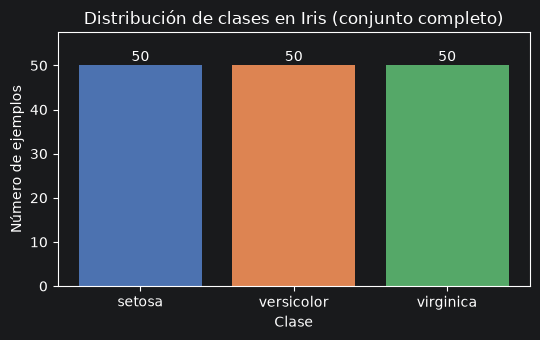


T1.5 — Partición 60/20/20 estratificada (declarada antes de entrenar)


,Partición,Tamaño,setosa,versicolor,virginica
1,entrenamiento,90,30,30,30
2,validación,30,10,10,10
3,prueba,30,10,10,10



Huella de E1 (debe repetirse en cada ejecución desde cero): 689602a2376f3020


In [20]:
# [E1.1] Load Iris with scikit-learn and check the shapes
iris = load_iris()
X_iris, y_iris = iris.data, iris.target
assert X_iris.shape == (150, 4), "Iris feature matrix must be 150 x 4"
assert y_iris.shape == (150,), "Iris label vector must have 150 entries"
feature_names = list(iris.feature_names)
class_names = iris.target_names.tolist()
class_codes = np.unique(y_iris)

# [E1.2] Descriptive tables T1.1-T1.3 (generated from the loaded data)
FEATURE_MEANING = {
    "sepal length (cm)": "longitud del sépalo, en centímetros",
    "sepal width (cm)": "ancho del sépalo, en centímetros",
    "petal length (cm)": "longitud del pétalo, en centímetros",
    "petal width (cm)": "ancho del pétalo, en centímetros",
}
assert list(FEATURE_MEANING) == feature_names, "every feature name must have a Spanish meaning"

t11 = make_table([
    ["Qué representa cada instancia", "Una flor de iris (una observación)"],
    ["Número de instancias", X_iris.shape[0]],
    ["Número de características", X_iris.shape[1]],
    ["Forma de la matriz de características X", str(X_iris.shape)],
    ["Forma del vector de etiquetas y", str(y_iris.shape)],
], ["Concepto", "Valor"])
t12 = make_table([[name, FEATURE_MEANING[name]] for name in feature_names],
                 ["Característica (nombre de la librería)", "Significado"])
t13 = make_table([[name, int(np.sum(y_iris == code))] for code, name in zip(class_codes, class_names)],
                 ["Clase", "Ejemplos"])
print("T1.1 — Descripción general del dataset Iris")
display(t11)
print("\nT1.2 — Características")
display(t12)
print("\nT1.3 — Clases y número de ejemplos por clase")
display(t13)

# [E1.3] Five random examples (single seed), all three classes guaranteed -> T1.4
example_idx = sample_examples(y_iris, 5, SEED)
assert set(y_iris[example_idx].tolist()) == set(class_codes.tolist()), "the 5 examples must include all classes"
t14 = make_table(
    [[int(i)] + X_iris[i].tolist() + [class_names[y_iris[i]]] for i in example_idx],
    ["Índice"] + feature_names + ["Clase"])
print("\nT1.4 — Cinco ejemplos elegidos al azar con la semilla única")
display(t14)

# [E1.4] Class distribution of the complete dataset -> F1.1
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(class_names, t13["Ejemplos"].to_numpy(), color=["#4c72b0", "#dd8452", "#55a868"])
ax.set_title("Distribución de clases en Iris (conjunto completo)")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de ejemplos")
ax.set_ylim(0, t13["Ejemplos"].max() * 1.15)
for pos, count in enumerate(t13["Ejemplos"]):
    ax.text(pos, count + 1, str(count), ha="center")
plt.tight_layout()
plt.show()

# [E1.5] Partition declared once, before any model is trained -> T1.5
splits_iris = make_splits(y_iris, stratify=True, seed=SEED)
assert [len(splits_iris[k]) for k in ("train", "val", "test")] == [90, 30, 30], "sizes must be 90/30/30"
all_idx = np.concatenate([splits_iris["train"], splits_iris["val"], splits_iris["test"]])
assert sorted(all_idx.tolist()) == list(range(150)), "partitions must be disjoint and complete"
summary_iris = split_summary(y_iris, splits_iris, class_names)
t15 = make_table(summary_iris.to_numpy().tolist(), list(summary_iris.columns))
assert list(t15.columns) == ["Partición", "Tamaño"] + class_names, "T1.5 columns"
assert (t15.iloc[1:][class_names].to_numpy() == 10).all(), "validation and test must hold 10 per class"
print("\nT1.5 — Partición 60/20/20 estratificada (declarada antes de entrenar)")
display(t15)

# [E1.6] Reproducibility fingerprint of E1
fingerprint_e1 = result_digest(X_iris[example_idx], example_idx, splits_iris["train"],
                               splits_iris["val"], splits_iris["test"])
print("\nHuella de E1 (debe repetirse en cada ejecución desde cero):", fingerprint_e1)

## E1.I — Interpretación del experimento 1

### ¿Están las clases balanceadas y qué implica para las métricas?

**Sí, están perfectamente balanceadas**: las tres clases (`setosa`, `versicolor`, `virginica`) tienen 50 ejemplos cada una (T1.3 y F1.1). La partición estratificada conserva esa proporción: 30/10/10 ejemplos por clase en entrenamiento, validación y prueba (T1.5).

Qué implica para elegir métricas:

- Sin clase mayoritaria, un clasificador que predijera siempre la misma clase acertaría alrededor de 1/3 de las veces; la **accuracy no queda inflada por el desbalance** y es interpretable.
- Aun así, el tamaño importa más que el balance: con 10 ejemplos por clase en validación y en prueba (30 en total), **un solo ejemplo mal clasificado cambia la accuracy en 1/30 ≈ 0.033**. Las diferencias pequeñas entre modelos serán difíciles de distinguir del azar de la partición.
- Usaré **F1 macro como métrica de decisión** porque promedia las clases por igual y no depende de que una clase domine, y **accuracy como apoyo**. Que ambas coincidan o no en un experimento concreto es algo que se comprobará con resultados (E2), no algo que el balance garantice.

### Contraste con la predicción de E1.P

| Predicción | Resultado | Veredicto |
|---|---|---|
| ~150 instancias y 4 características; X de 150 × 4 e y de 150 entradas | 150 instancias, 4 características, X `(150, 4)` e y `(150,)` (T1.1) | **Confirmada** |
| 3 clases con 50 ejemplos cada una (balanceado) | 50, 50 y 50 (T1.3, F1.1) | **Confirmada** |
| Partición 60/20/20 estratificada: 90/30/30 y 30/10/10 por clase | 90/30/30 y 30/10/10 por clase (T1.5) | **Confirmada** |
| «Un único ejemplo mal clasificado moverá las métricas de forma visible» | Un ejemplo vale 1/30 ≈ 0.033 de accuracy con 30 instancias | **Consistente por construcción**; se comprobará con resultados reales en E2 |

La predicción era sobre un dataset muy conocido, así que acertar no sorprende: lo que aporta el ejercicio es dejar explícito, antes de modelar, el tamaño de la muestra con el que se tomarán las decisiones.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

## E2.P — Predicciones iniciales del experimento 2 (antes de implementar)

Registro mis predicciones **antes** de implementar. Este texto no se modifica después de ejecutar la implementación de E2.

### 1. Sensibilidad a la escala de las características

Espero que sean **sensibles a la escala** los modelos que optimizan una función de pérdida con gradientes o penalizan la magnitud de los pesos: la **regresión logística**, la **SVM lineal** y el **MLP**. Espero que sean **poco sensibles** el **árbol de decisión**, el **Random Forest** y el **Gradient Boosting** (sus particiones dependen solo del orden de los valores de cada característica) y **Gaussian Naive Bayes** (estima una media y una varianza por característica y clase).

Predicción verificable con el diagnóstico sin estandarizar: espero que el F1 macro de validación del árbol y del Random Forest sea prácticamente el mismo con y sin estandarizar, y que si alguno cambia visiblemente sea el MLP o la SVM lineal. Como las cuatro características de Iris están en la misma unidad (centímetros), espero diferencias pequeñas en general.

### 2. Fronteras de decisión más simples (predicción conceptual)

Espero que la **SVM lineal** produzca las fronteras de decisión más simples: hiperplanos (rectas en el plano de dos características). La regresión logística multiclase debería ser igual de simple. Esta predicción es conceptual: se contrastará razonando sobre la forma de cada modelo, no con una medición directa.

### 3. Por qué no se puede saber de antemano cuál será el mejor

No hay un modelo que gane siempre: el resultado depende de la forma de los datos, del ruido, del tamaño de la muestra, de los hiperparámetros elegidos y del azar de la partición. Con solo 30 instancias de prueba, una diferencia de uno o dos ejemplos puede cambiar el orden. Espero ver los siete modelos entre 0.90 y 1.00 de accuracy en validación y en prueba, con diferencias de uno a tres ejemplos entre ellos.

### Criterio para «¿cuál fue el modelo más sencillo de programar?»

Lo respondo con un criterio objetivo, declarado antes de implementar:

> **Puntaje de sencillez = número de hiperparámetros fijados explícitamente en la configuración final + número de configuraciones probadas.**
> Un hiperparámetro «fijado explícitamente» es el que escribo en la configuración, aunque coincida con el valor por defecto. Menor puntaje = más sencillo.

Criterio de decisión en validación: F1 macro; desempate 1.º accuracy, 2.º la configuración probada primero.
Configuraciones declaradas por modelo (inicial incluida): {'Gaussian Naive Bayes': 3, 'Regresión logística': 3, 'SVM lineal': 3, 'Árbol de decisión': 3, 'Random Forest': 3, 'Gradient Boosting': 3, 'MLP': 4}

T2.1 — Configuración inicial, características estandarizadas (validación)


,Modelo,Accuracy de validación,F1 macro de validación
1,Gaussian Naive Bayes,0.9333,0.9333
2,Regresión logística,0.9333,0.9333
3,SVM lineal,0.8333,0.8329
4,Árbol de decisión,0.9000,0.8997
5,Random Forest,0.9333,0.9333
6,Gradient Boosting,0.9333,0.9333
7,MLP,0.9333,0.9333



T2.2 — Diagnóstico de sensibilidad a la escala (validación; no cuenta como configuración)


,Modelo,Accuracy sin estandarizar (validación),F1 macro sin estandarizar (validación),F1 macro estandarizado (validación),Diferencia de F1 macro
1,Gaussian Naive Bayes,0.9333,0.9333,0.9333,0.0000
2,Regresión logística,0.9333,0.9333,0.9333,0.0000
3,SVM lineal,0.8667,0.8667,0.8329,-0.0338
4,Árbol de decisión,0.9000,0.8997,0.8997,0.0000
5,Random Forest,0.9333,0.9333,0.9333,0.0000
6,Gradient Boosting,0.9333,0.9333,0.9333,0.0000
7,MLP,0.9667,0.9666,0.9333,-0.0332



T2.3 — Configuraciones probadas y elegida (N.º 1 = configuración inicial; validación)


...

,Modelo,Transformación,Hiperparámetros fijados,Configuraciones probadas
1,Gaussian Naive Bayes,Estandarización (StandardScaler),var_smoothing=1e-09,3
2,Regresión logística,Estandarización (StandardScaler),"C=1.0, max_iter=1000",3
3,SVM lineal,Estandarización (StandardScaler),"C=10.0, max_iter=10000",3
4,Árbol de decisión,Estandarización (StandardScaler),max_depth=5,3
5,Random Forest,Estandarización (StandardScaler),"n_estimators=100, max_depth=3",3
6,Gradient Boosting,Estandarización (StandardScaler),"n_estimators=100, learning_rate=0.1, max_depth=2",3
7,MLP,Estandarización (StandardScaler),"hidden_layer_sizes=(16,), max_iter=2000",4



T2.5 — Resultados en prueba (evaluación única de las configuraciones congeladas)


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
1,Gaussian Naive Bayes,Estandarización (StandardScaler),var_smoothing=1e-09,0.9333,0.9333
2,Regresión logística,Estandarización (StandardScaler),"C=1.0, max_iter=1000",0.9333,0.9333
3,SVM lineal,Estandarización (StandardScaler),"C=10.0, max_iter=10000",0.8667,0.8653
4,Árbol de decisión,Estandarización (StandardScaler),max_depth=5,0.9333,0.9333
5,Random Forest,Estandarización (StandardScaler),"n_estimators=100, max_depth=3",0.9333,0.9333
6,Gradient Boosting,Estandarización (StandardScaler),"n_estimators=100, learning_rate=0.1, max_depth=2",0.9333,0.9333
7,MLP,Estandarización (StandardScaler),"hidden_layer_sizes=(16,), max_iter=2000",0.9333,0.9333



T2.6 — F1 micro y F1 macro de prueba


,Modelo,F1 micro de prueba,F1 macro de prueba
1,Gaussian Naive Bayes,0.9333,0.9333
2,Regresión logística,0.9333,0.9333
3,SVM lineal,0.8667,0.8653
4,Árbol de decisión,0.9333,0.9333
5,Random Forest,0.9333,0.9333
6,Gradient Boosting,0.9333,0.9333
7,MLP,0.9333,0.9333


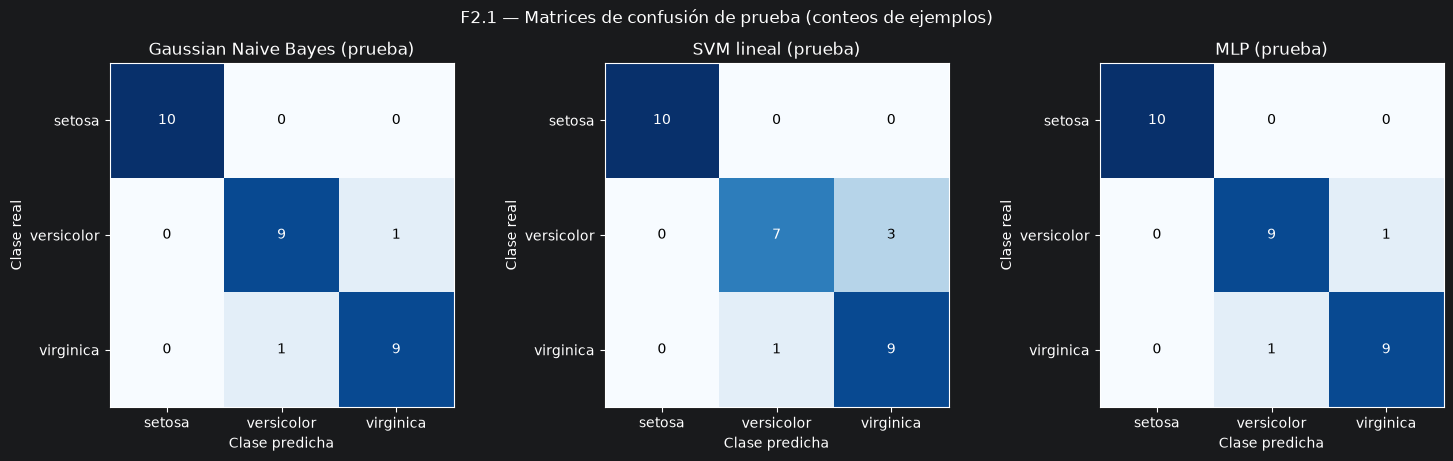


Mejor observado por F1 macro de prueba (apoyo: accuracy): Gaussian Naive Bayes — «mejor observado, no seleccionado».
Mejor observado por accuracy: Gaussian Naive Bayes (coincide con el de F1 macro).
No distinguibles del mejor (≤ 1 error de prueba): ['Regresión logística', 'Árbol de decisión', 'Random Forest', 'Gradient Boosting', 'MLP']
Modelos más sencillos de programar según el criterio declarado: ['Gaussian Naive Bayes', 'Árbol de decisión']

T2.7 — Comparación de cada modelo contra el mejor observado


,Modelo,Errores de prueba,Diferencia con el mejor observado,No distinguible del mejor (≤ 1 error)
1,Gaussian Naive Bayes,2,0,— (es el mejor observado)
2,Regresión logística,2,0,Sí
3,SVM lineal,4,2,No
4,Árbol de decisión,2,0,Sí
5,Random Forest,2,0,Sí
6,Gradient Boosting,2,0,Sí
7,MLP,2,0,Sí



T2.8 — Orden por F1 macro y por accuracy (prueba)


,Modelo,Posición por F1 macro,Posición por accuracy,¿Coincide?
1,Gaussian Naive Bayes,1,1,Sí
2,Regresión logística,1,1,Sí
3,SVM lineal,7,7,Sí
4,Árbol de decisión,1,1,Sí
5,Random Forest,1,1,Sí
6,Gradient Boosting,1,1,Sí
7,MLP,1,1,Sí



T2.9 — Criterio de sencillez declarado en E2.P


...


T2.12 — Errores de clasificación analizados


,Instancia (índice original),Partición,Modelo,Otros modelos que también fallaron,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Clase real,Clase predicha,Nota
1,77,prueba,Gaussian Naive Bayes,6,6.7,3.0,5.0,1.7,versicolor,virginica,
2,134,prueba,Gaussian Naive Bayes,6,6.1,2.6,5.6,1.4,virginica,versicolor,



T2.12b — Referencia: media de cada característica por clase (entrenamiento)


,Clase (media en entrenamiento),sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
1,setosa,4.94,3.3367,1.4600,0.2500
2,versicolor,5.96,2.7233,4.2400,1.3000
3,virginica,6.61,2.9800,5.5533,2.0433



Huella de E2 (debe repetirse en cada ejecución desde cero): db54a3c0be16c4a4


In [21]:
# [E2.0] Declaration, made before any fit: initial configurations, alternatives and test switch
RUN_TEST = True  # was False while tuning; switched on only after the configurations were frozen

# One initial configuration per model, written explicitly (the seed is injected by the factory).
INITIAL = {
    "gaussian_nb": {"var_smoothing": 1e-9},
    "logistic_regression": {"C": 1.0, "max_iter": 1000},
    "linear_svm": {"C": 1.0, "max_iter": 10000},
    "decision_tree": {"max_depth": 3},
    "random_forest": {"n_estimators": 100, "max_depth": 3},
    "gradient_boosting": {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 2},
    "mlp": {"hidden_layer_sizes": (16,), "max_iter": 2000},
}
# At most 3 alternatives per model, so that MAX_CONFIGS = 4 counts the initial one.
ALTERNATIVES = {
    "gaussian_nb": [{"var_smoothing": 1e-7}, {"var_smoothing": 1e-5}],
    "logistic_regression": [{"C": 0.1, "max_iter": 1000}, {"C": 10.0, "max_iter": 1000}],
    "linear_svm": [{"C": 0.1, "max_iter": 10000}, {"C": 10.0, "max_iter": 10000}],
    "decision_tree": [{"max_depth": 2}, {"max_depth": 5}],
    "random_forest": [{"n_estimators": 50, "max_depth": 3}, {"n_estimators": 200, "max_depth": 5}],
    "gradient_boosting": [{"n_estimators": 50, "learning_rate": 0.1, "max_depth": 2},
                          {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 3}],
    "mlp": [{"hidden_layer_sizes": (8,), "max_iter": 2000},
            {"hidden_layer_sizes": (32,), "max_iter": 2000},
            {"hidden_layer_sizes": (16,), "max_iter": 5000}],
}
for key in CLF_KEYS:
    declared = [INITIAL[key]] + ALTERNATIVES[key]
    assert len(declared) <= MAX_CONFIGS, f"{key}: more than MAX_CONFIGS configurations"
    assert all(declared[i] != declared[j] for i in range(len(declared)) for j in range(i)), \
        f"{key}: configurations must be distinct"
    assert all("random_state" not in config for config in declared), f"{key}: the seed is not part of a config"
print("Criterio de decisión en validación: F1 macro; desempate 1.º accuracy, 2.º la configuración probada primero.")
print("Configuraciones declaradas por modelo (inicial incluida):",
      {CLF_LABELS[k]: 1 + len(ALTERNATIVES[k]) for k in CLF_KEYS})

# [E2.1] Initial configuration of every model, fitted on train and scored on validation -> T2.1
X_train, y_train = X_iris[splits_iris["train"]], y_iris[splits_iris["train"]]
X_val, y_val = X_iris[splits_iris["val"]], y_iris[splits_iris["val"]]

COLS_T21 = ["Modelo", "Accuracy de validación", "F1 macro de validación"]
records = {key: [] for key in CLF_KEYS}
for key in CLF_KEYS:
    est = build_classifier(key, INITIAL[key], SEED, scaled=True)
    result = train_and_score(est, X_train, y_train, X_val, y_val, score_classifier)
    records[key].append({"model": key, "order": 0, "config": INITIAL[key], **result,
                         "degenerate": is_degenerate_cls(result["y_pred"], class_codes)})
t21 = make_table([[CLF_LABELS[k], records[k][0]["accuracy"], records[k][0]["f1_macro"]] for k in CLF_KEYS],
                 COLS_T21)
assert list(t21.columns) == COLS_T21 and len(t21) == 7, "T2.1 must have 7 rows and the exact columns"
print("\nT2.1 — Configuración inicial, características estandarizadas (validación)")
display(t21)

# [E2.2] Diagnostic without standardizing (validation only; not a configuration) -> T2.2
n_records_before = {k: len(v) for k, v in records.items()}
diagnostic = {}
for key in CLF_KEYS:
    est = build_classifier(key, INITIAL[key], SEED, scaled=False)
    diagnostic[key] = train_and_score(est, X_train, y_train, X_val, y_val, score_classifier)
assert {k: len(v) for k, v in records.items()} == n_records_before, "the diagnostic must not add records"
COLS_T22 = ["Modelo", "Accuracy sin estandarizar (validación)", "F1 macro sin estandarizar (validación)",
            "F1 macro estandarizado (validación)", "Diferencia de F1 macro"]
t22 = make_table(
    [[CLF_LABELS[k], diagnostic[k]["accuracy"], diagnostic[k]["f1_macro"], records[k][0]["f1_macro"],
      records[k][0]["f1_macro"] - diagnostic[k]["f1_macro"]] for k in CLF_KEYS], COLS_T22)
assert list(t22.columns) == COLS_T22, "T2.2 columns"
print("\nT2.2 — Diagnóstico de sensibilidad a la escala (validación; no cuenta como configuración)")
display(t22)

# [E2.3] Limited tuning: alternatives fitted on train, decided on validation only -> T2.3
for key in CLF_KEYS:
    for order, config in enumerate(ALTERNATIVES[key], start=1):
        est = build_classifier(key, config, SEED, scaled=True)
        result = train_and_score(est, X_train, y_train, X_val, y_val, score_classifier)
        records[key].append({"model": key, "order": order, "config": config, **result,
                             "degenerate": is_degenerate_cls(result["y_pred"], class_codes)})
chosen = {k: select_config(records[k], "f1_macro", "accuracy", higher_is_better=True) for k in CLF_KEYS}
assert all(1 <= len(records[k]) <= MAX_CONFIGS for k in CLF_KEYS), "at most MAX_CONFIGS records per model"

COLS_T23 = ["Modelo", "N.º", "Hiperparámetros", "Accuracy de validación", "F1 macro de validación",
            "Avisos", "Elegida"]
rows_t23 = []
for key in CLF_KEYS:
    for rec in records[key]:
        rows_t23.append([CLF_LABELS[key], rec["order"] + 1, format_config(rec["config"]),
                         rec["accuracy"], rec["f1_macro"],
                         format_warnings(rec["warnings_fit"] + rec["warnings_eval"]),
                         "Sí" if rec is chosen[key] else ""])
t23 = make_table(rows_t23, COLS_T23)
assert sum(row[-1] == "Sí" for row in rows_t23) == len(CLF_KEYS), "exactly one chosen configuration per model"
print("\nT2.3 — Configuraciones probadas y elegida (N.º 1 = configuración inicial; validación)")
display(t23)

# [E2.4] Freeze: chosen configuration + estimator fitted on train only; no refit -> T2.4
frozen = {k: freeze(k, chosen[k], len(records[k])) for k in CLF_KEYS}
for key in CLF_KEYS:
    _, check, _ = score_classifier(frozen[key].estimator, X_val, y_val)
    assert check["f1_macro"] == chosen[key]["f1_macro"] and check["accuracy"] == chosen[key]["accuracy"], \
        f"{key}: the frozen model must reproduce its validation record"
COLS_T24 = ["Modelo", "Transformación", "Hiperparámetros fijados", "Configuraciones probadas"]
t24 = make_table([[CLF_LABELS[k], "Estandarización (StandardScaler)", format_config(frozen[k].config),
                   frozen[k].n_configs] for k in CLF_KEYS], COLS_T24)
print("\nT2.4 — Configuraciones congeladas (ajustadas solo con entrenamiento)")
display(t24)

if not RUN_TEST:
    print("\nRUN_TEST = False: la partición de prueba no se ha usado todavía.")
else:
    # [E2.5] Single evaluation of the frozen models on the same test partition -> T2.5, T2.6, F2.1
    X_test, y_test = X_iris[splits_iris["test"]], y_iris[splits_iris["test"]]
    ledger = set()
    test_res = {k: evaluate_once(frozen[k], X_test, y_test, ledger, score_classifier) for k in CLF_KEYS}
    assert len(ledger) == len(CLF_KEYS) == 7, "every model must be evaluated exactly once on test"

    COLS_T25 = ["Modelo", "Transformación", "Hiperparámetros principales", "Accuracy de prueba",
                "F1 macro de prueba"]
    t25 = make_table([[CLF_LABELS[k], "Estandarización (StandardScaler)", format_config(frozen[k].config),
                       test_res[k]["accuracy"], test_res[k]["f1_macro"]] for k in CLF_KEYS], COLS_T25)
    COLS_T26 = ["Modelo", "F1 micro de prueba", "F1 macro de prueba"]
    t26 = make_table([[CLF_LABELS[k], test_res[k]["f1_micro"], test_res[k]["f1_macro"]] for k in CLF_KEYS],
                     COLS_T26)
    print("\nT2.5 — Resultados en prueba (evaluación única de las configuraciones congeladas)")
    display(t25)
    print("\nT2.6 — F1 micro y F1 macro de prueba")
    display(t26)

    cm_keys = ["gaussian_nb", "linear_svm", "mlp"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    for ax, key in zip(axes, cm_keys):
        cm = confusion_matrix(y_test, test_res[key]["y_pred"], labels=class_codes)
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(1, cm.max()))
        ax.set_xticks(range(len(class_names)), labels=class_names)
        ax.set_yticks(range(len(class_names)), labels=class_names)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_title(f"{CLF_LABELS[key]} (prueba)")
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")
    fig.suptitle("F2.1 — Matrices de confusión de prueba (conteos de ejemplos)")
    plt.tight_layout()
    plt.show()

    # [E2.6] Comparison against the best observed model (not between pairs) -> T2.7, T2.8, T2.9
    errors_test = {k: int(np.sum(test_res[k]["y_pred"] != y_test)) for k in CLF_KEYS}
    best_rows = [{"model": k, "order": i, "f1_macro": test_res[k]["f1_macro"],
                  "accuracy": test_res[k]["accuracy"]} for i, k in enumerate(CLF_KEYS)]
    best_obs = select_config(best_rows, "f1_macro", "accuracy", higher_is_better=True)["model"]
    best_by_accuracy = select_config(best_rows, "accuracy", "f1_macro", higher_is_better=True)["model"]
    not_distinguishable = indistinguishable_cls(errors_test, best_obs, tol=1)
    COLS_T27 = ["Modelo", "Errores de prueba", "Diferencia con el mejor observado",
                "No distinguible del mejor (≤ 1 error)"]
    rows_t27 = []
    for key in CLF_KEYS:
        if key == best_obs:
            verdict = "— (es el mejor observado)"
        else:
            verdict = "Sí" if key in not_distinguishable else "No"
        rows_t27.append([CLF_LABELS[key], errors_test[key], errors_test[key] - errors_test[best_obs], verdict])
    t27 = make_table(rows_t27, COLS_T27)

    rank_f1 = rank_models({k: test_res[k]["f1_macro"] for k in CLF_KEYS}, higher_is_better=True)
    rank_acc = rank_models({k: test_res[k]["accuracy"] for k in CLF_KEYS}, higher_is_better=True)
    COLS_T28 = ["Modelo", "Posición por F1 macro", "Posición por accuracy", "¿Coincide?"]
    t28 = make_table([[CLF_LABELS[k], rank_f1[k], rank_acc[k], "Sí" if rank_f1[k] == rank_acc[k] else "No"]
                      for k in CLF_KEYS], COLS_T28)

    COLS_T29 = ["Modelo", "Hiperparámetros fijados", "Configuraciones probadas", "Suma (menor = más sencillo)"]
    t29 = make_table([[CLF_LABELS[k], len(frozen[k].config), frozen[k].n_configs, simplicity_score(frozen[k])]
                      for k in CLF_KEYS], COLS_T29)
    min_score = min(simplicity_score(frozen[k]) for k in CLF_KEYS)
    simplest = [CLF_LABELS[k] for k in CLF_KEYS if simplicity_score(frozen[k]) == min_score]

    print(f"\nMejor observado por F1 macro de prueba (apoyo: accuracy): {CLF_LABELS[best_obs]} "
          f"— «mejor observado, no seleccionado».")
    print(f"Mejor observado por accuracy: {CLF_LABELS[best_by_accuracy]} "
          f"({'coincide' if best_by_accuracy == best_obs else 'DISCREPA'} con el de F1 macro).")
    print("No distinguibles del mejor (≤ 1 error de prueba):",
          [CLF_LABELS[k] for k in not_distinguishable] or "ninguno")
    print("Modelos más sencillos de programar según el criterio declarado:", simplest)
    print("\nT2.7 — Comparación de cada modelo contra el mejor observado")
    display(t27)
    print("\nT2.8 — Orden por F1 macro y por accuracy (prueba)")
    display(t28)
    print("\nT2.9 — Criterio de sencillez declarado en E2.P")
    display(t29)

    # [E2.7] Warnings and degenerate results, shown as they were captured -> T2.10, T2.11
    COLS_T210 = ["Modelo", "Etapa (ajuste / validación / prueba)", "Categoría", "Mensaje"]
    rows_t210 = []
    for key in CLF_KEYS:
        label = CLF_LABELS[key]
        for rec in records[key]:
            tag = f"[configuración {rec['order'] + 1}] "
            rows_t210 += [[label, "ajuste", w["category"], tag + w["message"]] for w in rec["warnings_fit"]]
            rows_t210 += [[label, "validación", w["category"], tag + w["message"]] for w in rec["warnings_eval"]]
        tag = "[diagnóstico sin estandarizar] "
        rows_t210 += [[label, "ajuste", w["category"], tag + w["message"]] for w in diagnostic[key]["warnings_fit"]]
        rows_t210 += [[label, "validación", w["category"], tag + w["message"]]
                      for w in diagnostic[key]["warnings_eval"]]
        rows_t210 += [[label, "prueba", w["category"], w["message"]] for w in test_res[key]["warnings_eval"]]
    t210 = make_table(rows_t210, COLS_T210)
    COLS_T211 = ["Modelo", "Clases nunca predichas (prueba)", "Degenerado"]
    never = {k: never_predicted_classes(test_res[k]["y_pred"], class_codes) for k in CLF_KEYS}
    t211 = make_table([[CLF_LABELS[k], ", ".join(class_names[c] for c in never[k]) or "ninguna",
                        "Sí" if is_degenerate_cls(test_res[k]["y_pred"], class_codes) else "No"]
                       for k in CLF_KEYS], COLS_T211)
    print("\nT2.10 — Avisos capturados (ajuste, validación y prueba)")
    if len(t210):
        display(t210)
    else:
        print("Sin avisos: ningún modelo emitió avisos al ajustarse ni al evaluarse.")
    print("\nT2.11 — Resultados degenerados (clases que un modelo nunca predice)")
    display(t211)

    # [E2.8] Two classification errors, chosen by the rule declared in the plan -> T2.12
    pred_test = {k: test_res[k]["y_pred"] for k in CLF_KEYS}
    pred_val = {k: chosen[k]["y_pred"] for k in CLF_KEYS}
    picked = pick_two_errors(pred_test, pred_val, y_test, y_val, CLF_KEYS,
                             splits_iris["test"], splits_iris["val"])
    COLS_T212 = (["Instancia (índice original)", "Partición", "Modelo", "Otros modelos que también fallaron"]
                 + feature_names + ["Clase real", "Clase predicha", "Nota"])
    rows_t212 = []
    for err in picked:
        source = pred_test if err["partition"] == "prueba" else pred_val
        rows_t212.append([err["index"], err["partition"], CLF_LABELS[err["model"]], err["also_failed"]]
                         + X_iris[err["index"]].tolist()
                         + [class_names[y_iris[err["index"]]],
                            class_names[source[err["model"]][err["position"]]], err["note"]])
    t212 = make_table(rows_t212, COLS_T212)
    print("\nT2.12 — Errores de clasificación analizados")
    if picked:
        display(t212)
    else:
        print("No hay errores de clasificación ni en prueba ni en validación: no hay instancias que analizar.")
    # Descriptive reference for reading the errors (train means per class; does not alter any configuration).
    t212_ref = make_table([[class_names[c]] + X_train[y_train == c].mean(axis=0).tolist() for c in class_codes],
                          ["Clase (media en entrenamiento)"] + feature_names)
    print("\nT2.12b — Referencia: media de cada característica por clase (entrenamiento)")
    display(t212_ref)

    # [E2.9] Integrity checks and reproducibility fingerprint of E2
    assert all(len(records[k][0]["y_pred"]) == len(y_val) for k in CLF_KEYS), "same validation partition"
    assert all(len(test_res[k]["y_pred"]) == len(y_test) for k in CLF_KEYS), "same test partition"
    assert all(len(records[k]) <= MAX_CONFIGS for k in CLF_KEYS), "at most MAX_CONFIGS configurations"
    assert len(ledger) == 7, "seven single test evaluations"
    assert list(t25.columns) == ["Modelo", "Transformación", "Hiperparámetros principales",
                                 "Accuracy de prueba", "F1 macro de prueba"], "T2.5 columns"
    fingerprint_e2 = result_digest(
        t21[COLS_T21[1:]].to_numpy(dtype=float),
        t23[["Accuracy de validación", "F1 macro de validación"]].to_numpy(dtype=float),
        t25[["Accuracy de prueba", "F1 macro de prueba"]].to_numpy(dtype=float),
        np.concatenate([test_res[k]["y_pred"] for k in CLF_KEYS]))
    print("\nHuella de E2 (debe repetirse en cada ejecución desde cero):", fingerprint_e2)

## E2.I — Interpretación del experimento 2

Todas las cifras citadas salen de las tablas y figuras de la celda E2.C. Cada conclusión vale **en esta partición** (90/30/30, una sola semilla): con 30 instancias de prueba, un ejemplo equivale a 0.033 de accuracy.

### 1. ¿Cuál fue el modelo con el mejor desempeño?

- **Mejor observado, no seleccionado: Gaussian Naive Bayes**, con 0.9333 de accuracy y 0.9333 de F1 macro en prueba (2 errores; T2.5 y T2.7). El rótulo importa: no se usó para elegir nada.
- Ese primer puesto es **un empate exacto** que se resuelve solo por el orden de la lista de modelos. La regresión logística, el árbol de decisión, el Random Forest, el Gradient Boosting y el MLP tienen **los mismos 2 errores** (diferencia 0 con el mejor, T2.7), así que son **no distinguibles del mejor** en esta partición.
- La **SVM lineal** quedó con 4 errores de prueba (accuracy 0.8667; F1 macro 0.8653): 2 errores más que el mejor, fuera del umbral de ≤ 1 error de T2.7. Aun así, una diferencia de dos ejemplos sobre 30 no es una prueba de significancia: el umbral es un criterio práctico, no una prueba estadística.
- La accuracy **no discrepa** del F1 macro en quién es el mejor observado (T2.8: el orden de los siete modelos es el mismo con ambas métricas).
- No puedo nombrar un ganador firme: seis modelos de familias muy distintas (probabilístico, lineal, árbol, ensambles y red neuronal) rinden igual en esta muestra.

### 2. ¿Cuál fue el modelo más sencillo de programar?

Con el criterio declarado en E2.P (hiperparámetros fijados explícitamente + configuraciones probadas), **Gaussian Naive Bayes y el árbol de decisión empatan con 4 puntos** (1 hiperparámetro fijado + 3 configuraciones probadas; T2.9). Les siguen la regresión logística, la SVM lineal y el Random Forest con 5, y el Gradient Boosting y el MLP con 6 (el MLP probó 4 configuraciones y el Gradient Boosting fijó 3 hiperparámetros).

Lo observado respalda la respuesta: el diagnóstico de T2.2 muestra que ambos modelos dan **exactamente el mismo F1 macro con y sin estandarizar** (diferencia 0.0000), es decir, no necesitan paso de preprocesamiento para funcionar bien aquí.

### 3. ¿Accuracy y F1 macro cuentan la misma historia?

**En esta partición, sí**: las posiciones por accuracy y por F1 macro coinciden para los siete modelos (T2.8): seis comparten el primer puesto y la SVM lineal es la séptima con ambas. No presumo que el balance de clases lo garantice: coinciden porque, con 10 ejemplos por clase en prueba y errores de este tamaño, los errores no cambian el orden. Con otra partición, otra semilla o clases desbalanceadas el orden podría diferir.

### 4. Diferencia entre las métricas macro y micro

- **F1 macro**: calcula el F1 de cada clase y promedia con el **mismo peso para cada clase**, sin importar cuántos ejemplos tenga.
- **F1 micro**: cuenta los verdaderos positivos, falsos positivos y falsos negativos de **todas las clases juntas**; pesa cada ejemplo por igual. En clasificación multiclase de una sola etiqueta, el F1 micro **coincide con la accuracy**: T2.6 muestra 0.9333 y 0.8667, los mismos valores que T2.5.
- A cuatro decimales, la diferencia entre ambos promedios solo aparece en la SVM lineal (0.8667 de F1 micro frente a 0.8653 de F1 macro), es decir, alrededor de 0.001. Es pequeña porque las tres clases tienen el mismo número de ejemplos en prueba (10); con clases desbalanceadas la brecha podría ser mayor.

### 5. ¿Qué aporta el MLP frente a un modelo lineal?

En este dataset y esta partición, **el MLP no aporta una ventaja medible**: obtiene lo mismo que la regresión logística (0.9333; mismos 2 errores) y supera a la SVM lineal (0.8667), pero esa diferencia con la SVM no se debe a la no linealidad por sí sola, porque la regresión logística también es lineal y rinde igual que el MLP. El MLP puede en principio modelar fronteras no lineales, pero aquí solo hay 2 errores en 30 instancias de prueba y ambos son compartidos por todos los modelos (sección 6), de modo que esa capacidad no tiene dónde manifestarse. A cambio, el MLP exige más decisiones (tamaño de la capa oculta, `max_iter`) y tuvo la mayor cantidad de configuraciones probadas (T2.3). **No afirmo una ventaja general del MLP**: solo que aquí no se observa.

### 6. Dos errores de clasificación (T2.12 y T2.12b)

Las dos instancias de prueba mal clasificadas, que además fallaron **los siete modelos** (6 modelos más en cada una), son:

| Instancia | Clase real → predicha | Características (largo/ancho sépalo; largo/ancho pétalo) |
|---|---|---|
| 77 | versicolor → virginica | 6.7, 3.0; 5.0, 1.7 |
| 134 | virginica → versicolor | 6.1, 2.6; 5.6, 1.4 |

**Lo que los datos permiten concluir**

- Los dos errores cruzan la frontera **versicolor ↔ virginica**, y los siete modelos (de familias distintas) se equivocan en ambas instancias.
- Comparadas con las medias por clase de entrenamiento (T2.12b), los cuatro valores de la instancia 77 están más cerca de la media de virginica que de la de versicolor (por ejemplo, largo del pétalo 5.0 frente a 4.24 y 5.55), y en la instancia 134 tres de las cuatro características están más cerca de versicolor (largo del sépalo 6.1, ancho del sépalo 2.6 y ancho del pétalo 1.4); solo el largo del pétalo (5.6) es típico de virginica. Es decir, ambas flores tienen un **perfil mixto** y el modelo predijo la clase que sus medidas sugieren.
- Que fallen todos los modelos indica que la dificultad está **en la instancia**, no en un algoritmo concreto.
- En F2.1, Naive Bayes y el MLP cometen exactamente esos dos errores (uno de versicolor → virginica y otro de virginica → versicolor). La SVM lineal comete esos dos y **dos más, ambos de versicolor → virginica** (3 de esa dirección y 1 de la otra). Setosa no se confunde en ninguna de las tres matrices mostradas.

**Lo que no puedo concluir (hipótesis no verificadas)**

- *Hipótesis:* las clases se solapan de forma natural en esa zona del espacio de características. Dos ejemplos no bastan para afirmarlo.
- *Hipótesis:* podría tratarse de flores atípicas, de un error de medición o de una etiqueta dudosa. No hay en el notebook nada que lo compruebe.
- Con dos ejemplos tampoco puedo afirmar que la frontera versicolor/virginica sea «la» fuente general de error, ni generalizar a otros datos: son evidencia anecdótica de dos casos.
- El modelo que aparece en T2.12 (Gaussian Naive Bayes) es solo el primero de la lista que falló en esa instancia; no significa que ese modelo sea especialmente malo.

Estos errores **no se usaron para modificar ninguna configuración** (las configuraciones estaban congeladas desde T2.4).

### 7. Avisos y resultados degenerados

T2.10 está vacía: **ningún modelo emitió avisos** al ajustarse ni al evaluarse (con `max_iter` fijado explícitamente en regresión logística, SVM lineal y MLP). T2.11 muestra que **ningún clasificador es degenerado**: todos predicen las tres clases en prueba.

### 8. Contraste con las predicciones de E2.P

| Predicción | Resultado | Veredicto |
|---|---|---|
| **(falsable)** Sensibles a la escala: regresión logística, SVM lineal y MLP; poco sensibles: árbol, Random Forest, Gradient Boosting y Naive Bayes | T2.2: árbol, Random Forest, Gradient Boosting y Naive Bayes cambian **0.0000** de F1 macro. SVM lineal y MLP cambian cerca de 0.034 (un ejemplo de 30). La **regresión logística también cambia 0.0000** | **Confirmada en 6 de 7 modelos; contradicha en la regresión logística** (no se mostró sensible). En SVM lineal y MLP el modelo sin estandarizar fue incluso ligeramente mejor en validación |
| **(conceptual)** La SVM lineal produce las fronteras más simples (hiperplanos) | No hay medición directa. La SVM lineal y la regresión logística tienen la misma forma de frontera; la SVM rindió menos (0.8667 frente a 0.9333) | **Respaldada por razonamiento, no medida**; lo observado no la contradice, pero el menor rendimiento de la SVM no puede atribuirse solo a su linealidad |
| **(conceptual)** No se puede saber de antemano quién gana | Seis modelos empataron exactamente en prueba y la SVM quedó a 2 ejemplos | **Respaldada**: el orden depende de ejemplos concretos y de la partición |
| **(falsable)** Los siete modelos entre 0.90 y 1.00 de accuracy en validación y prueba, con diferencias de uno a tres ejemplos | Seis modelos con 0.9333 en validación (configuración elegida, T2.3) y en prueba (T2.5); la **SVM lineal quedó en 0.8667** en ambas | **Parcialmente contradicha**: la SVM lineal cayó por debajo de 0.90; las diferencias entre modelos fueron de 0 a 2 ejemplos, tanto en validación como en prueba |

### 9. Decisiones justificadas

- **Configuración elegida.** Se eligió con F1 macro de validación y, en empate, con accuracy y luego con la configuración probada primero (T2.3). Hubo empates exactos en Naive Bayes, regresión logística, Random Forest, Gradient Boosting y MLP: ganó la configuración inicial en todos. Las únicas alternativas que mejoraron a la inicial fueron la SVM lineal (`C=10.0`, de 0.8329 a 0.8667) y el árbol (`max_depth=5`, de 0.8997 a 0.9333).
- **Errores analizados.** Los de prueba con más modelos fallando, desempatados por menor índice original; aquí había dos y no hizo falta completar con validación.
- **Prueba.** Se evaluó una vez por modelo y no motivó ningún nuevo ajuste.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

## E3.P — Predicciones iniciales del experimento 3 (antes de implementar)

Registro mis predicciones **antes** de implementar. Este texto no se modifica después de ejecutar la implementación de E3.

### (a) ¿Un modelo más flexible produce siempre menor error en datos nuevos?

Considero **más flexibles** al **MLP**, al **Gradient Boosting**, al **Random Forest** y al **árbol de regresión**, y **menos flexible** a la **regresión lineal** (Ridge y Lasso la restringen aún más).

Mi predicción es que **no**: más flexibilidad no garantiza menor error en datos nuevos. Diabetes tiene pocas instancias (442) y bastante ruido, así que espero que los modelos más flexibles sobreajusten y que la regresión lineal, Ridge o Lasso queden a un nivel parecido o mejor en RMSE de prueba.

Formulada en observable: espero que el **RMSE de prueba del MLP** (el modelo que declaro más flexible) **no sea menor** que el de la **regresión lineal** (la menos flexible).

### (b) Efecto de aumentar la penalización en Ridge y Lasso

Al aumentar la intensidad de la penalización (alpha) espero que:

- **Ridge:** la norma de los coeficientes **disminuya de forma suave** hacia cero sin anular ninguno de forma exacta.
- **Lasso:** los coeficientes **pasen a cero uno a uno**, hasta anularse todos con un alpha suficientemente grande.
- **Error de entrenamiento:** **aumente** de forma monótona con alpha.
- **Error de validación:** **baje un poco o se mantenga** al principio y **suba** después; el mínimo debería estar en un alpha intermedio-pequeño, no en un extremo de la rejilla.
- **Brecha** entre entrenamiento y validación: se **reduzca** al aumentar alpha.

Criterio de decisión en validación: RMSE; desempate 1.º MAE, 2.º la configuración probada primero.
Rejilla de alpha de Ridge: [0.01, 0.0316, 0.1, 0.3162, 1.0, 3.1623, 10.0, 31.6228, 100.0, 316.2278, 1000.0, 3162.2777, 10000.0]
Rejilla de alpha de Lasso: [0.001, 0.0032, 0.01, 0.0316, 0.1, 0.3162, 1.0, 3.1623, 10.0, 31.6228, 100.0]
T3.1 — Dataset Diabetes: variables, objetivo y transformación de origen


,Variable,Descripción (según el dataset)
1,age,"edad, en años"
2,sex,sexo
3,bmi,índice de masa corporal
4,bp,presión arterial media
5,s1,tc: colesterol sérico total
6,s2,ldl: lipoproteínas de baja densidad
7,s3,hdl: lipoproteínas de alta densidad
8,s4,tch: colesterol total / HDL
9,s5,ltg: posiblemente el logaritmo del nivel de triglicéridos séricos
10,s6,glu: nivel de azúcar en sangre



T3.2 — Partición 60/20/20 (sin estratificar: el objetivo es numérico)


,Partición,Tamaño
1,entrenamiento,264
2,validación,89
3,prueba,89



Limitación declarada (fuga de origen): las 10 variables ya vienen centradas y escaladas con estadísticos
del conjunto completo, antes de la partición. No es controlable desde el notebook; por eso se muestran
«tal como vienen» y no se interpretan como unidades originales.
Objetivo: solo el MLP lo transforma (StandardScaler ajustado con entrenamiento y revertido antes de las
métricas); el resto de los modelos no transforma el objetivo.

T3.3 — Barrido de la intensidad de penalización (entrenamiento y validación)


,Modelo,Intensidad (alpha),Norma L2 de los coeficientes,Coeficientes nulos,RMSE de entrenamiento,RMSE de validación
1,Ridge,0.0100,77.8515,—,54.6104,51.1916
2,Ridge,0.0316,77.2777,—,54.6104,51.1870
3,Ridge,0.1000,75.5491,—,54.6110,51.1741
4,Ridge,0.3162,70.8260,—,54.6159,51.1433
5,Ridge,1.0000,60.8803,—,54.6438,51.1031
6,Ridge,3.1623,48.7953,—,54.7267,51.1106
7,Ridge,10.0000,41.9169,—,54.8426,51.1605
8,Ridge,31.6228,38.2868,—,55.0288,51.2258
9,Ridge,100.0000,32.7782,—,55.8594,51.7369
10,Ridge,316.2278,23.6688,—,59.0416,54.3361


Ridge: mejor alpha de validación = 1.0000, en el interior de la rejilla.
Lasso: mejor alpha de validación = 3.1623, en el interior de la rejilla.


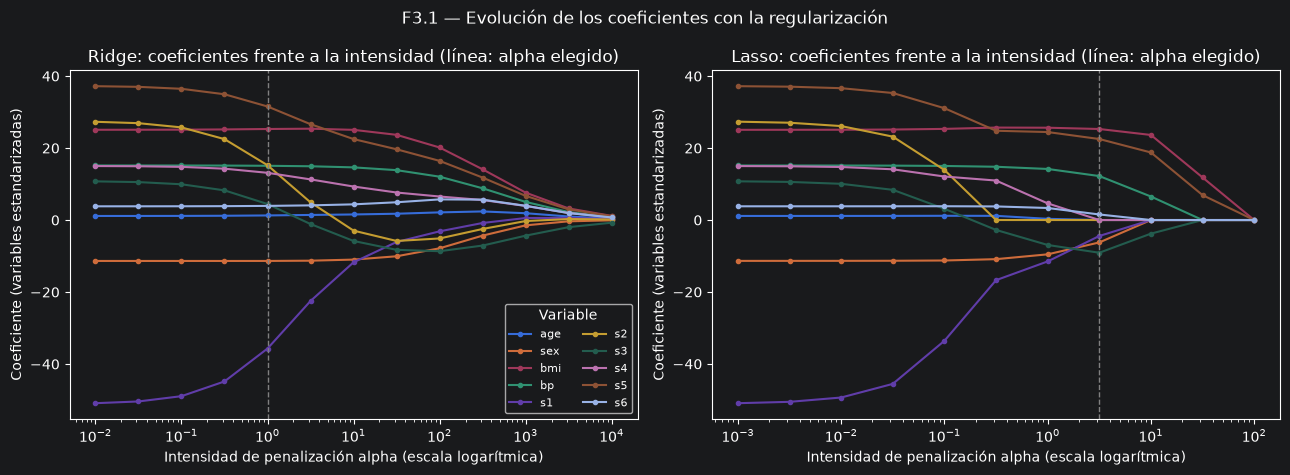

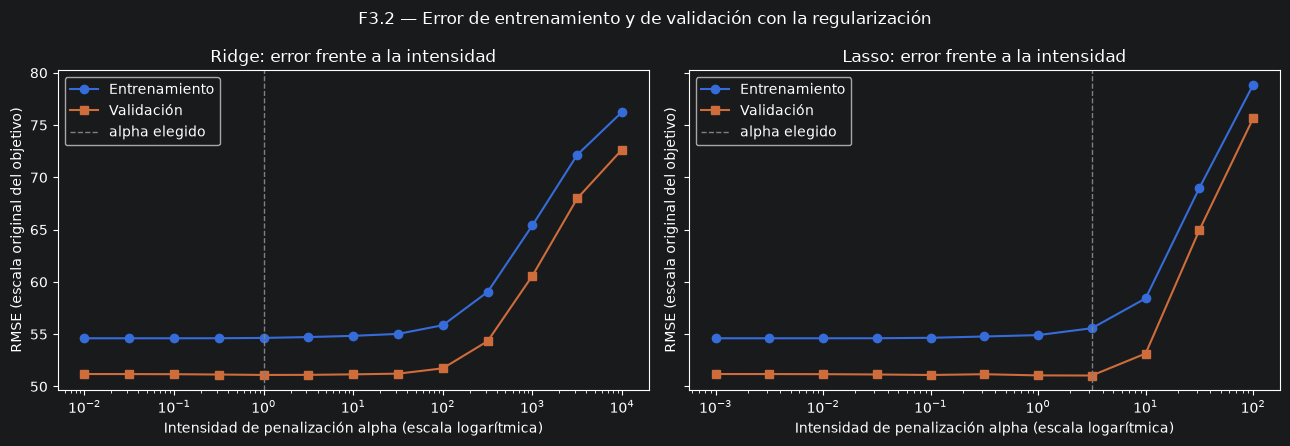


T3.4 — Configuraciones probadas y elegida (N.º 1 = inicial; Ridge y Lasso: alpha del barrido)


,Modelo,N.º,Hiperparámetros,RMSE de validación,MAE de validación,Avisos,Elegida
1,Regresión lineal,1,fit_intercept=True,51.1937,42.9389,—,Sí
2,Regresión lineal,2,fit_intercept=False,179.4020,170.4621,—,
3,Ridge,1,"solver=auto, alpha=1.0",51.1031,42.7230,—,Sí
4,Lasso,1,"max_iter=10000, alpha=3.16228",51.0484,42.7193,—,Sí
5,kNN,1,n_neighbors=5,56.8333,45.2921,—,
6,kNN,2,n_neighbors=10,54.6390,43.8618,—,
7,kNN,3,n_neighbors=20,54.5540,45.5579,—,Sí
8,Árbol de regresión,1,max_depth=3,58.2267,46.5692,—,Sí
9,Árbol de regresión,2,max_depth=2,58.7814,46.6805,—,
10,Árbol de regresión,3,max_depth=5,59.4434,47.0798,—,



T3.5 — Configuraciones congeladas (ajustadas solo con entrenamiento)


,Modelo,Transformación,Hiperparámetros fijados,Configuraciones probadas
1,Regresión lineal,Ninguna (variables ya escaladas por el proveedor),fit_intercept=True,2
2,Ridge,Estandarización de las variables (pipeline),"solver=auto, alpha=1.0",1
3,Lasso,Estandarización de las variables (pipeline),"max_iter=10000, alpha=3.16228",1
4,kNN,Estandarización de las variables (pipeline),n_neighbors=20,3
5,Árbol de regresión,Ninguna (variables ya escaladas por el proveedor),max_depth=3,3
6,Random Forest,Ninguna (variables ya escaladas por el proveedor),"n_estimators=100, max_depth=3",3
7,Gradient Boosting,Ninguna (variables ya escaladas por el proveedor),"n_estimators=50, learning_rate=0.1, max_depth=2",3
8,MLP,Estandarización de variables y del objetivo (revertida antes de las métricas),"hidden_layer_sizes=(16,), max_iter=2000",4



T3.6 — Resultados en prueba (evaluación única de las configuraciones congeladas)


...

,Modelo,RMSE de prueba,Diferencia relativa con el mejor,No distinguible del mejor (≤ 5 %)
1,Regresión lineal,54.1564,0.0484,Sí
2,Ridge,54.0309,0.0460,Sí
3,Lasso,52.8182,0.0225,Sí
4,kNN,55.8598,0.0814,No
5,Árbol de regresión,60.2482,0.1663,No
6,Random Forest,53.7638,0.0408,Sí
7,Gradient Boosting,52.8627,0.0234,Sí
8,MLP,51.6564,0.0000,— (es el mejor observado)



T3.8 — Posición de cada modelo según RMSE, MAE y R²


,Modelo,Posición por RMSE,Posición por MAE,Posición por R²
1,Regresión lineal,6,3,6
2,Ridge,5,4,5
3,Lasso,2,2,2
4,kNN,7,7,7
5,Árbol de regresión,8,8,8
6,Random Forest,4,5,4
7,Gradient Boosting,3,6,3
8,MLP,1,1,1



T3.10 — R² de la predicción trivial (promedio)


,Predictor,R² de prueba
1,Media de entrenamiento (predicción trivial),-0.0031
2,Media de los datos de prueba (referencia del R²),0.0000


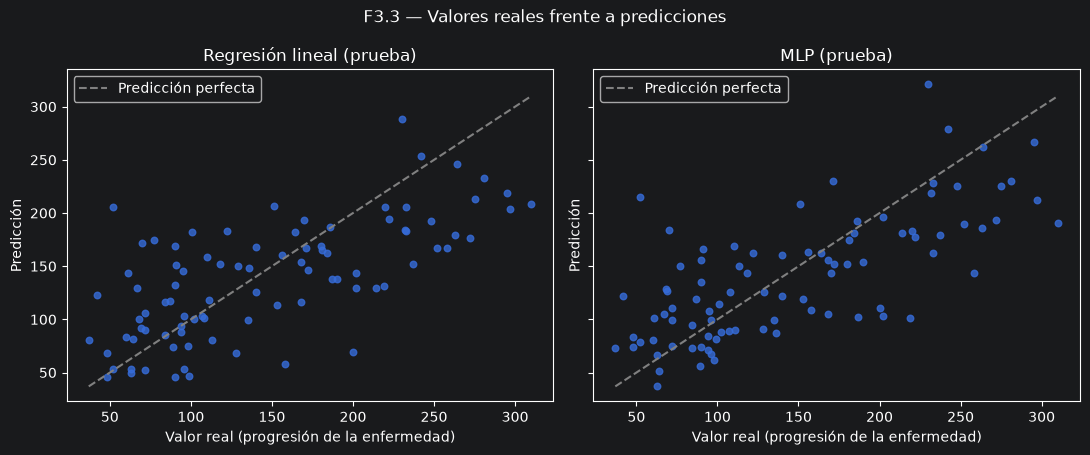

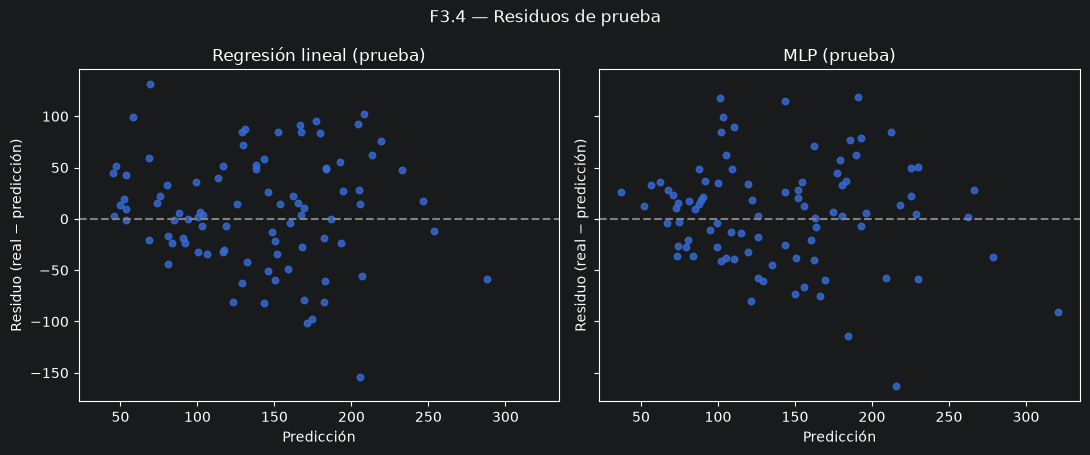


T3.9 — Los dos ejemplos de prueba con mayor error absoluto por modelo (Error = real − predicción, igual que el residuo de F3.4; variables tal como vienen)


,Modelo,Instancia (índice original),Valor real,Predicción,Error,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
1,Regresión lineal,56,52.0,205.6562,-153.6562,-0.0418,-0.0446,0.0412,-0.0263,-0.0318,-0.0304,-0.0360,0.0029,0.0337,-0.0176
2,Regresión lineal,77,200.0,68.9715,131.0285,-0.0963,-0.0446,-0.0364,-0.0745,-0.0387,-0.0276,0.0155,-0.0395,-0.0741,-0.0011
3,MLP,56,52.0,215.2795,-163.2795,-0.0418,-0.0446,0.0412,-0.0263,-0.0318,-0.0304,-0.0360,0.0029,0.0337,-0.0176
4,MLP,9,310.0,191.0684,118.9316,-0.0709,-0.0446,0.0391,-0.0332,-0.0126,-0.0345,-0.0250,-0.0026,0.0677,-0.0135



T3.11 — Avisos capturados (barrido, ajuste, validación y prueba)
Sin avisos: ningún modelo emitió avisos al ajustarse ni al evaluarse.

T3.12 — Resultados degenerados


,Modelo,Degenerado,Motivo
1,Regresión lineal (congelado),No,—
2,Ridge (congelado),No,—
3,Lasso (congelado),No,—
4,kNN (congelado),No,—
5,Árbol de regresión (congelado),No,—
6,Random Forest (congelado),No,—
7,Gradient Boosting (congelado),No,—
8,MLP (congelado),No,—
9,"Lasso (barrido, alpha=100)",Sí,"todos los coeficientes en cero: predictor constante, esperado a intensidades altas"



Huella de E3 (debe repetirse en cada ejecución desde cero): 762c72766081749c


In [22]:
# [E3.0] Declaration, made before any fit: configurations, alpha grids and test switch
RUN_TEST = True  # was False while tuning; switched on only after the configurations were frozen

# Initial configuration and alternatives (<= 3) for the six models without an alpha sweep.
REG_INITIAL = {
    "linear_regression": {"fit_intercept": True},
    "knn": {"n_neighbors": 5},
    "decision_tree": {"max_depth": 3},
    "random_forest": {"n_estimators": 100, "max_depth": 5},
    "gradient_boosting": {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 2},
    "mlp": {"hidden_layer_sizes": (32,), "max_iter": 2000},
}
REG_ALTERNATIVES = {
    "linear_regression": [{"fit_intercept": False}],
    "knn": [{"n_neighbors": 10}, {"n_neighbors": 20}],
    "decision_tree": [{"max_depth": 2}, {"max_depth": 5}],
    "random_forest": [{"n_estimators": 100, "max_depth": 3}, {"n_estimators": 200, "max_depth": 8}],
    "gradient_boosting": [{"n_estimators": 50, "learning_rate": 0.1, "max_depth": 2},
                          {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 3}],
    "mlp": [{"hidden_layer_sizes": (16,), "max_iter": 2000},
            {"hidden_layer_sizes": (64,), "max_iter": 2000},
            {"hidden_layer_sizes": (32,), "max_iter": 5000}],
}
# Ridge and Lasso: non-alpha hyperparameters (<= 4 configurations); alpha comes from the sweep.
NON_ALPHA_CONFIGS = {"ridge": [{"solver": "auto"}], "lasso": [{"max_iter": 10000}]}
# One log-spaced grid per model, declared before seeing any result (Lasso must reach all-zero).
ALPHA_GRID = {"ridge": np.logspace(-2, 4, 13), "lasso": np.logspace(-3, 2, 11)}

for key, declared_configs in ((k, [REG_INITIAL[k]] + REG_ALTERNATIVES[k]) for k in REG_INITIAL):
    assert len(declared_configs) <= MAX_CONFIGS, f"{key}: more than MAX_CONFIGS configurations"
    assert all(declared_configs[i] != declared_configs[j]
               for i in range(len(declared_configs)) for j in range(i)), f"{key}: configurations must be distinct"
for key, grid in ALPHA_GRID.items():
    ratios = grid[1:] / grid[:-1]
    assert len(grid) >= 8 and np.allclose(ratios, ratios[0]), f"{key}: grid must be log-spaced with >= 8 points"
    assert len(NON_ALPHA_CONFIGS[key]) <= MAX_CONFIGS, f"{key}: more than MAX_CONFIGS non-alpha configurations"
print("Criterio de decisión en validación: RMSE; desempate 1.º MAE, 2.º la configuración probada primero.")
print("Rejilla de alpha de Ridge:", ALPHA_GRID["ridge"].round(4).tolist())
print("Rejilla de alpha de Lasso:", ALPHA_GRID["lasso"].round(4).tolist())

# [E3.1] Load Diabetes (default variant) and describe it -> T3.1
diabetes = load_diabetes()
X_diab, y_diab = diabetes.data, diabetes.target
assert X_diab.shape == (442, 10), "Diabetes feature matrix must be 442 x 10"
assert y_diab.shape == (442,), "Diabetes target vector must have 442 entries"
diab_features = list(diabetes.feature_names)
DIAB_MEANING = {
    "age": "edad, en años",
    "sex": "sexo",
    "bmi": "índice de masa corporal",
    "bp": "presión arterial media",
    "s1": "tc: colesterol sérico total",
    "s2": "ldl: lipoproteínas de baja densidad",
    "s3": "hdl: lipoproteínas de alta densidad",
    "s4": "tch: colesterol total / HDL",
    "s5": "ltg: posiblemente el logaritmo del nivel de triglicéridos séricos",
    "s6": "glu: nivel de azúcar en sangre",
}
assert list(DIAB_MEANING) == diab_features, "every variable must have a Spanish description"
descr_lines = [line.strip() for line in diabetes.DESCR.splitlines() if "mean centered" in line]
assert descr_lines, "the dataset description must mention the centering and scaling"
col_sum_sq = (X_diab ** 2).sum(axis=0)
col_mean = X_diab.mean(axis=0)
assert np.allclose(col_sum_sq, 1.0, atol=1e-6), "each column must have sum of squares 1"
assert np.allclose(col_mean, 0.0, atol=1e-8), "each column must be centered"
t31_rows = [[name, DIAB_MEANING[name]] for name in diab_features]
t31_rows += [
    ["Objetivo (y)", "Medida cuantitativa de la progresión de la enfermedad un año después de la línea base "
                     f"(mínimo {y_diab.min():.0f}, máximo {y_diab.max():.0f})"],
    ["Transformación de origen (según DESCR)", descr_lines[0]],
    ["Comprobación numérica sobre X",
     f"suma de cuadrados por columna entre {col_sum_sq.min():.6f} y {col_sum_sq.max():.6f}; "
     f"|media| máxima por columna = {np.abs(col_mean).max():.2e}"],
]
t31 = make_table(t31_rows, ["Variable", "Descripción (según el dataset)"])
print("T3.1 — Dataset Diabetes: variables, objetivo y transformación de origen")
display(t31)

# [E3.2] Partition declared once, before any model is trained (not stratified) -> T3.2
splits_diab = make_splits(y_diab, stratify=False, seed=SEED)
assert [len(splits_diab[k]) for k in ("train", "val", "test")] == [264, 89, 89], "sizes must be 264/89/89"
all_idx_d = np.concatenate([splits_diab["train"], splits_diab["val"], splits_diab["test"]])
assert sorted(all_idx_d.tolist()) == list(range(442)), "partitions must be disjoint and complete"
t32 = make_table([[PARTITION_LABELS[k], len(splits_diab[k])] for k in ("train", "val", "test")],
                 ["Partición", "Tamaño"])
print("\nT3.2 — Partición 60/20/20 (sin estratificar: el objetivo es numérico)")
display(t32)

# [E3.3] Declarations required by the protocol
print("\nLimitación declarada (fuga de origen): las 10 variables ya vienen centradas y escaladas con estadísticos")
print("del conjunto completo, antes de la partición. No es controlable desde el notebook; por eso se muestran")
print("«tal como vienen» y no se interpretan como unidades originales.")
print("Objetivo: solo el MLP lo transforma (StandardScaler ajustado con entrenamiento y revertido antes de las")
print("métricas); el resto de los modelos no transforma el objetivo.")

# [E3.4] Alpha sweep of Ridge and Lasso on validation; the test partition is not used -> T3.3, F3.1, F3.2
X_tr, y_tr = X_diab[splits_diab["train"]], y_diab[splits_diab["train"]]
X_va, y_va = X_diab[splits_diab["val"]], y_diab[splits_diab["val"]]
sweep_data = {"X_fit": X_tr, "y_fit": y_tr, "X_eval": X_va, "y_eval": y_va}
sweeps = {key: alpha_sweep(key, NON_ALPHA_CONFIGS[key][0], ALPHA_GRID[key], sweep_data, SEED)
          for key in ("ridge", "lasso")}
assert len(sweeps["lasso"][-1]["coef"]) == X_diab.shape[1]
assert sweeps["lasso"][-1]["n_zero"] == X_diab.shape[1], "Lasso must reach the all-zero regime at the top of its grid"
ridge_norms = [row["l2_norm"] for row in sweeps["ridge"]]
assert all(a >= b - 1e-12 for a, b in zip(ridge_norms, ridge_norms[1:])), "Ridge L2 norm must not grow with alpha"

COLS_T33 = ["Modelo", "Intensidad (alpha)", "Norma L2 de los coeficientes", "Coeficientes nulos",
            "RMSE de entrenamiento", "RMSE de validación"]
rows_t33 = []
for key in ("ridge", "lasso"):
    for row in sweeps[key]:
        rows_t33.append([REG_LABELS[key], row["alpha"], row["l2_norm"],
                         row["n_zero"] if key == "lasso" else "—", row["rmse_train"], row["rmse_val"]])
t33 = make_table(rows_t33, COLS_T33)
best_alpha = {key: pick_best_alpha(sweeps[key]) for key in ("ridge", "lasso")}
print("\nT3.3 — Barrido de la intensidad de penalización (entrenamiento y validación)")
display(t33)
for key in ("ridge", "lasso"):
    edge = "EN EL BORDE de la rejilla (no se extiende)" if best_alpha[key]["at_border"] else "en el interior de la rejilla"
    print(f"{REG_LABELS[key]}: mejor alpha de validación = {best_alpha[key]['alpha']:.4f}, {edge}.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, key in zip(axes, ("ridge", "lasso")):
    alphas = [row["alpha"] for row in sweeps[key]]
    coefs = np.array([row["coef"] for row in sweeps[key]])
    for j, name in enumerate(diab_features):
        ax.plot(alphas, coefs[:, j], marker="o", markersize=3, label=name)
    ax.axvline(best_alpha[key]["alpha"], color="gray", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_title(f"{REG_LABELS[key]}: coeficientes frente a la intensidad (línea: alpha elegido)")
    ax.set_xlabel("Intensidad de penalización alpha (escala logarítmica)")
    ax.set_ylabel("Coeficiente (variables estandarizadas)")
axes[0].legend(ncol=2, fontsize=8, title="Variable")
fig.suptitle("F3.1 — Evolución de los coeficientes con la regularización")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, key in zip(axes, ("ridge", "lasso")):
    alphas = [row["alpha"] for row in sweeps[key]]
    ax.plot(alphas, [row["rmse_train"] for row in sweeps[key]], marker="o", label="Entrenamiento")
    ax.plot(alphas, [row["rmse_val"] for row in sweeps[key]], marker="s", label="Validación")
    ax.axvline(best_alpha[key]["alpha"], color="gray", linestyle="--", linewidth=1, label="alpha elegido")
    ax.set_xscale("log")
    ax.set_title(f"{REG_LABELS[key]}: error frente a la intensidad")
    ax.set_xlabel("Intensidad de penalización alpha (escala logarítmica)")
    ax.set_ylabel("RMSE (escala original del objetivo)")
    ax.legend()
fig.suptitle("F3.2 — Error de entrenamiento y de validación con la regularización")
plt.tight_layout()
plt.show()

# [E3.5] Limited tuning of the eight models on validation -> T3.4
records_reg = {key: [] for key in REG_KEYS}
for key in ("ridge", "lasso"):
    row = best_alpha[key]["row"]
    y_pred_va, metrics_va, _ = score_regressor(row["estimator"], X_va, y_va)
    records_reg[key].append({"model": key, "order": 0, "config": row["config"], "estimator": row["estimator"],
                             "y_pred": y_pred_va, **metrics_va, "warnings_fit": row["warnings_fit"],
                             "warnings_eval": row["warnings_eval"],
                             "degenerate": is_degenerate_reg(row["estimator"])})
for key in REG_INITIAL:
    for order, config in enumerate([REG_INITIAL[key]] + REG_ALTERNATIVES[key]):
        est = build_regressor(key, config, SEED)
        result = train_and_score(est, X_tr, y_tr, X_va, y_va, score_regressor)
        records_reg[key].append({"model": key, "order": order, "config": config, **result,
                                 "degenerate": is_degenerate_reg(result["estimator"])})
chosen_reg = {k: select_config(records_reg[k], "rmse", "mae", higher_is_better=False) for k in REG_KEYS}
assert all(1 <= len(records_reg[k]) <= MAX_CONFIGS for k in REG_KEYS), "at most MAX_CONFIGS configurations"

COLS_T34 = ["Modelo", "N.º", "Hiperparámetros", "RMSE de validación", "MAE de validación", "Avisos", "Elegida"]
rows_t34 = []
for key in REG_KEYS:
    for rec in records_reg[key]:
        rows_t34.append([REG_LABELS[key], rec["order"] + 1, format_config(rec["config"]), rec["rmse"], rec["mae"],
                         format_warnings(rec["warnings_fit"] + rec["warnings_eval"]),
                         "Sí" if rec is chosen_reg[key] else ""])
t34 = make_table(rows_t34, COLS_T34)
assert sum(row[-1] == "Sí" for row in rows_t34) == len(REG_KEYS), "exactly one chosen configuration per model"
print("\nT3.4 — Configuraciones probadas y elegida (N.º 1 = inicial; Ridge y Lasso: alpha del barrido)")
display(t34)

# [E3.6] Freeze: chosen configuration + estimator fitted on train only; no refit -> T3.5
frozen_reg = {k: freeze(k, chosen_reg[k], len(records_reg[k])) for k in REG_KEYS}
for key in REG_KEYS:
    _, check, _ = score_regressor(frozen_reg[key].estimator, X_va, y_va)
    assert check["rmse"] == chosen_reg[key]["rmse"], f"{key}: the frozen model must reproduce its validation record"
TRANSFORM_LABEL = {key: "Estandarización de las variables (pipeline)" if key in SCALED_REGRESSORS
                   else "Ninguna (variables ya escaladas por el proveedor)" for key in REG_KEYS}
TRANSFORM_LABEL["mlp"] = "Estandarización de variables y del objetivo (revertida antes de las métricas)"
COLS_T35 = ["Modelo", "Transformación", "Hiperparámetros fijados", "Configuraciones probadas"]
t35 = make_table([[REG_LABELS[k], TRANSFORM_LABEL[k], format_config(frozen_reg[k].config), frozen_reg[k].n_configs]
                  for k in REG_KEYS], COLS_T35)
print("\nT3.5 — Configuraciones congeladas (ajustadas solo con entrenamiento)")
display(t35)

if not RUN_TEST:
    print("\nRUN_TEST = False: la partición de prueba no se ha usado todavía.")
else:
    # [E3.7] Single evaluation of the eight frozen models on the same test partition -> T3.6
    X_test, y_test = X_diab[splits_diab["test"]], y_diab[splits_diab["test"]]
    ledger_reg = set()
    test_reg = {k: evaluate_once(frozen_reg[k], X_test, y_test, ledger_reg, score_regressor) for k in REG_KEYS}
    assert len(ledger_reg) == len(REG_KEYS) == 8, "every model must be evaluated exactly once on test"
    COLS_T36 = ["Modelo", "MAE", "RMSE", "R²"]
    t36 = make_table([[REG_LABELS[k], test_reg[k]["mae"], test_reg[k]["rmse"], test_reg[k]["r2"]]
                      for k in REG_KEYS], COLS_T36)
    print("\nT3.6 — Resultados en prueba (evaluación única de las configuraciones congeladas)")
    display(t36)

    # [E3.8] Comparison against the best observed model, rankings and the R2 baseline -> T3.7, T3.8, T3.10
    best_rows_reg = [{"model": k, "order": i, "rmse": test_reg[k]["rmse"], "mae": test_reg[k]["mae"]}
                     for i, k in enumerate(REG_KEYS)]
    best_obs_reg = select_config(best_rows_reg, "rmse", "mae", higher_is_better=False)["model"]
    rmse_test = {k: test_reg[k]["rmse"] for k in REG_KEYS}
    not_dist_reg = indistinguishable_reg(rmse_test, best_obs_reg, tol=0.05)
    COLS_T37 = ["Modelo", "RMSE de prueba", "Diferencia relativa con el mejor", "No distinguible del mejor (≤ 5 %)"]
    rows_t37 = []
    for key in REG_KEYS:
        rel = (rmse_test[key] - rmse_test[best_obs_reg]) / rmse_test[best_obs_reg]
        if key == best_obs_reg:
            verdict = "— (es el mejor observado)"
        else:
            verdict = "Sí" if key in not_dist_reg else "No"
        rows_t37.append([REG_LABELS[key], rmse_test[key], rel, verdict])
    t37 = make_table(rows_t37, COLS_T37)

    rank_rmse = rank_models(rmse_test, higher_is_better=False)
    rank_mae = rank_models({k: test_reg[k]["mae"] for k in REG_KEYS}, higher_is_better=False)
    rank_r2 = rank_models({k: test_reg[k]["r2"] for k in REG_KEYS}, higher_is_better=True)
    assert rank_r2 == rank_rmse, "on the same partition the R2 order must equal the RMSE order"
    COLS_T38 = ["Modelo", "Posición por RMSE", "Posición por MAE", "Posición por R²"]
    t38 = make_table([[REG_LABELS[k], rank_rmse[k], rank_mae[k], rank_r2[k]] for k in REG_KEYS], COLS_T38)

    r2_train_mean = regression_metrics(y_test, np.full(len(y_test), y_tr.mean()))["r2"]
    r2_test_mean = regression_metrics(y_test, np.full(len(y_test), y_test.mean()))["r2"]
    assert r2_train_mean <= 1e-12, "predicting the train mean cannot beat the test mean (R2 <= 0)"
    assert abs(r2_test_mean) < 1e-12, "predicting the evaluated mean gives R2 = 0 by definition"
    COLS_T310 = ["Predictor", "R² de prueba"]
    t310 = make_table([["Media de entrenamiento (predicción trivial)", r2_train_mean],
                       ["Media de los datos de prueba (referencia del R²)", r2_test_mean]], COLS_T310)
    n_negative = sum(test_reg[k]["r2"] < 0 for k in REG_KEYS)

    print(f"\nMejor observado por RMSE de prueba (apoyo: MAE): {REG_LABELS[best_obs_reg]} "
          f"— «mejor observado, no seleccionado».")
    print("No distinguibles del mejor (≤ 5 % de su RMSE):", [REG_LABELS[k] for k in not_dist_reg] or "ninguno")
    print("Modelos con R² negativo en prueba:", n_negative)
    print("\nT3.7 — Comparación contra el mejor observado (RMSE de prueba)")
    display(t37)
    print("\nT3.8 — Posición de cada modelo según RMSE, MAE y R²")
    display(t38)
    print("\nT3.10 — R² de la predicción trivial (promedio)")
    display(t310)

    # [E3.9] Linear regression and MLP diagnostics on test -> F3.3, F3.4, T3.9
    diag_keys = ["linear_regression", "mlp"]
    lo, hi = float(y_test.min()), float(y_test.max())
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
    for ax, key in zip(axes, diag_keys):
        ax.scatter(y_test, test_reg[key]["y_pred"], s=22, alpha=0.8)
        ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", label="Predicción perfecta")
        ax.set_title(f"{REG_LABELS[key]} (prueba)")
        ax.set_xlabel("Valor real (progresión de la enfermedad)")
        ax.set_ylabel("Predicción")
        ax.legend()
    fig.suptitle("F3.3 — Valores reales frente a predicciones")
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
    for ax, key in zip(axes, diag_keys):
        pred = test_reg[key]["y_pred"]
        ax.scatter(pred, y_test - pred, s=22, alpha=0.8)
        ax.axhline(0.0, color="gray", linestyle="--")
        ax.set_title(f"{REG_LABELS[key]} (prueba)")
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Residuo (real − predicción)")
    fig.suptitle("F3.4 — Residuos de prueba")
    plt.tight_layout()
    plt.show()

    COLS_T39 = ["Modelo", "Instancia (índice original)", "Valor real", "Predicción", "Error"] + diab_features
    rows_t39 = []
    for key in diag_keys:
        pred = test_reg[key]["y_pred"]
        for pos in top_abs_errors(y_test, pred, k=2):
            idx = int(splits_diab["test"][pos])
            rows_t39.append([REG_LABELS[key], idx, float(y_test[pos]), float(pred[pos]),
                             float(y_test[pos] - pred[pos])] + X_diab[idx].tolist())
    t39 = make_table(rows_t39, COLS_T39)
    print("\nT3.9 — Los dos ejemplos de prueba con mayor error absoluto por modelo "
          "(Error = real − predicción, igual que el residuo de F3.4; variables tal como vienen)")
    display(t39)

    # [E3.10] Warnings and degenerate results -> T3.11, T3.12
    COLS_T311 = ["Modelo", "Etapa", "Categoría", "Mensaje"]
    rows_t311 = []
    for key in ("ridge", "lasso"):
        for row in sweeps[key]:
            tag = f"[barrido, alpha={row['alpha']:.4g}] "
            rows_t311 += [[REG_LABELS[key], "ajuste", w["category"], tag + w["message"]] for w in row["warnings_fit"]]
            rows_t311 += [[REG_LABELS[key], "validación", w["category"], tag + w["message"]]
                          for w in row["warnings_eval"]]
    for key in REG_INITIAL:
        for rec in records_reg[key]:
            tag = f"[configuración {rec['order'] + 1}] "
            rows_t311 += [[REG_LABELS[key], "ajuste", w["category"], tag + w["message"]] for w in rec["warnings_fit"]]
            rows_t311 += [[REG_LABELS[key], "validación", w["category"], tag + w["message"]]
                          for w in rec["warnings_eval"]]
    for key in REG_KEYS:
        rows_t311 += [[REG_LABELS[key], "prueba", w["category"], w["message"]] for w in test_reg[key]["warnings_eval"]]
    t311 = make_table(rows_t311, COLS_T311)

    COLS_T312 = ["Modelo", "Degenerado", "Motivo"]
    rows_t312 = []
    for key in REG_KEYS:
        flag = is_degenerate_reg(frozen_reg[key].estimator)
        rows_t312.append([REG_LABELS[key] + " (congelado)", "Sí" if flag else "No",
                          "todos los coeficientes en cero" if flag else "—"])
    for row in sweeps["lasso"]:
        if is_degenerate_reg(row["estimator"]):
            rows_t312.append([f"Lasso (barrido, alpha={row['alpha']:.4g})", "Sí",
                              "todos los coeficientes en cero: predictor constante, esperado a intensidades altas"])
    t312 = make_table(rows_t312, COLS_T312)
    print("\nT3.11 — Avisos capturados (barrido, ajuste, validación y prueba)")
    if len(t311):
        display(t311)
    else:
        print("Sin avisos: ningún modelo emitió avisos al ajustarse ni al evaluarse.")
    print("\nT3.12 — Resultados degenerados")
    display(t312)

    # [E3.11] Integrity checks and reproducibility fingerprint of E3
    assert all(len(records_reg[k]) <= MAX_CONFIGS for k in REG_KEYS), "at most MAX_CONFIGS configurations"
    assert list(t36.columns) == ["Modelo", "MAE", "RMSE", "R²"], "T3.6 columns"
    assert len(ledger_reg) == 8, "eight single test evaluations"
    assert X_diab.shape == (442, 10) and y_diab.shape == (442,), "dataset shapes"
    fingerprint_e3 = result_digest(
        np.array([[row["alpha"], row["l2_norm"], row["rmse_train"], row["rmse_val"]]
                  for key in ("ridge", "lasso") for row in sweeps[key]]),
        t34[["RMSE de validación", "MAE de validación"]].to_numpy(dtype=float),
        t36[["MAE", "RMSE", "R²"]].to_numpy(dtype=float),
        np.concatenate([test_reg[k]["y_pred"] for k in REG_KEYS]))
    print("\nHuella de E3 (debe repetirse en cada ejecución desde cero):", fingerprint_e3)

## E3.I — Interpretación del experimento 3

Todas las cifras salen de las tablas y figuras de la celda E3.C. Cada conclusión vale **en esta partición** (264/89/89, una sola semilla). Las 10 variables se muestran «tal como vienen» (ya centradas y escaladas por el proveedor): no son unidades originales.

### 1. ¿Qué modelo tuvo el mejor desempeño?

- **Mejor observado, no seleccionado: MLP**, con RMSE de prueba 51.66, MAE 40.45 y R² 0.4964 (T3.6 y T3.7).
- **No distinguibles del mejor** (RMSE a ≤ 5 % del 51.66 del MLP, es decir, hasta 54.24): Lasso (2.3 %), Gradient Boosting (2.3 %), Random Forest (4.1 %), Ridge (4.6 %) y regresión lineal (4.8 %), esta última casi en el umbral (T3.7). Quedan fuera kNN (8.1 %) y el árbol de regresión (16.6 %). No puedo declarar un ganador firme: es un criterio práctico, no una prueba de significancia.
- **MAE sí cambia el orden** (T3.8): el MLP es primero con ambas métricas, pero la regresión lineal es tercera por MAE y sexta por RMSE, y Gradient Boosting es tercero por RMSE y sexto por MAE.
- **R² ordena igual que RMSE** (T3.8). No es casualidad: sobre la misma partición, R² = 1 − SSE/SST y el SST es el mismo para todos los modelos, así que R² es una transformación decreciente del RMSE.
- Un dato de cautela: en **validación** el MLP elegido era peor que los modelos lineales (RMSE 55.56 frente a 51.10 de Ridge y 51.05 de Lasso, T3.4) y en **prueba** quedó primero. El orden cambia de una partición a otra, lo que refuerza que las diferencias de unos pocos puntos de RMSE no son robustas con 89 instancias.

### 2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?

El **MAE** promedia los errores en valor absoluto y trata todos por igual; el **RMSE** los eleva al cuadrado antes de promediar, así que **pesa mucho más los errores grandes**. Un modelo con pocos errores muy grandes sale peor en RMSE que en MAE, y uno con errores moderados y parejos, al revés.

Aquí los órdenes **difieren** (T3.8) y los datos lo ilustran: Gradient Boosting tiene mejor RMSE que la regresión lineal (52.86 frente a 54.16) pero peor MAE (43.34 frente a 42.92). Es coherente con que la regresión lineal acierta algo mejor en el error típico, pero comete algunos errores grandes que el RMSE castiga más (por ejemplo, los de T3.9).

### 3. ¿Cómo se interpreta un R² negativo?

R² compara el modelo con la **predicción trivial de predecir siempre el promedio de los datos evaluados**: R² = 1 − SSE/SST. Con R² = 1 no hay error; con R² = 0 el modelo no mejora al promedio; con **R² < 0 el modelo es peor que predecir ese promedio**. Además, predecir el promedio de entrenamiento da un R² ≤ 0 en prueba, porque ese promedio no coincide exactamente con el de prueba: T3.10 lo muestra con −0.0031.

**Ningún modelo obtuvo R² negativo**: van de 0.31 (árbol) a 0.50 (MLP) (T3.6), todos mejores que la predicción trivial. Aun así, ni el mejor explica la mitad de la variación del objetivo: el R² máximo es 0.4964.

### 4. ¿Qué efecto tuvo aumentar la regularización? (T3.3, F3.1, F3.2)

- **Magnitud de los coeficientes.** En Ridge, la norma L2 baja de forma continua de 77.85 (alpha = 0.01) a 2.25 (alpha = 10 000), sin llegar a cero. En Lasso baja de 77.91 a 0 (alpha = 100).
- **Coeficientes nulos en Lasso.** Aparecen de forma progresiva: 0 hasta alpha ≈ 0.1, 1 en 0.32 y 1.0, 3 en 3.16 (el alpha elegido), 6 en 10, 8 en 31.6 y **los 10 en alpha = 100** (predictor constante).
- **Error de entrenamiento.** Sube de forma monótona con alpha (Ridge: 54.61 → 76.25; Lasso: 54.61 → 78.85): más penalización significa menos capacidad de ajustar.
- **Error de validación.** Baja muy poco al principio y luego sube: mínimo en alpha = 1.0 para Ridge (51.10) y en alpha = 3.16 para Lasso (51.05), ambos en el **interior** de la rejilla (no cayó en el borde). La mejora frente a la penalización mínima es diminuta (≈ 0.1 puntos de RMSE): con 10 variables y 264 ejemplos de entrenamiento, los modelos lineales casi no sobreajustan.
- **Brecha entre entrenamiento y validación.** El RMSE de validación es **menor** que el de entrenamiento en todo el barrido (por ejemplo, Ridge con alpha = 1.0: 54.64 frente a 51.10). La diferencia no se reduce de forma sistemática al aumentar alpha: crece de 3.4 hasta ≈ 4.8 (alpha = 1000) y vuelve a ≈ 3.6 (alpha = 10 000). No hay signo de sobreajuste que la regularización corrija; la diferencia refleja más bien que esta partición de validación resulta algo más fácil que la de entrenamiento.

### 5. ¿Qué puede explicar los errores grandes? (T3.9, F3.3, F3.4)

Aquí el error es **real − predicción** (el mismo signo que el residuo de F3.4: negativo = el modelo sobreestima). Los mayores errores absolutos de prueba son: instancia **56** (real 52.0; la regresión lineal predice 205.7 y el MLP 215.3, es decir, errores de −153.7 y −163.3: ambos sobreestiman mucho), instancia **77** (real 200.0, la regresión lineal predice 69.0: error de +131.0) e instancia **9** (real 310.0, el MLP predice 191.1: error de +118.9).

Explicaciones posibles:

- **Información insuficiente en las 10 variables.** Incluso el mejor modelo deja sin explicar más de la mitad de la variación (R² máximo 0.4964, T3.6). Es esperable que haya pacientes con evolución muy distinta a la que sugieren sus variables. *Es una hipótesis razonable, respaldada por el R² pero no comprobada caso a caso.*
- **Instancia difícil para todos los modelos.** La instancia 56 produce el mayor error en la regresión lineal y en el MLP, dos modelos de naturaleza distinta, lo que apunta a que el problema está en el paciente y no en el algoritmo. *Hipótesis: con solo dos modelos no puede afirmarse.*
- **Valores extremos del objetivo.** Los reales 52 y 310 están en los extremos del rango (25–346, T3.1), donde un modelo que se aproxima al promedio se equivoca más. *Hipótesis: no medida aquí.*
- **Ruido de medición o factores no registrados** (por ejemplo, tratamiento o hábitos de los pacientes). *Hipótesis sin verificar: el dataset no incluye esa información.*

### 6. ¿Un coeficiente predictivo demuestra una relación causal?

**No.** Un coeficiente de un modelo predictivo resume una **asociación** entre una variable y el objetivo en estos datos, no el efecto de intervenir sobre ella. Motivos concretos:

- **Variables correlacionadas entre sí.** Si dos variables aportan información parecida, el modelo puede repartir su efecto entre ellas o asignárselo a una sola, y el coeficiente individual depende de qué otras variables estén en el modelo. Lasso lo muestra con claridad: en el alpha elegido anula 3 de los 10 coeficientes (T3.3) y eso **no** significa que esas variables no tengan efecto, solo que su aporte se puede sustituir con las demás. F3.1 lo refuerza (lectura aproximada de la figura): con la penalización mínima `s1` tiene un coeficiente grande y negativo (≈ −51) y `s2` uno grande y positivo (≈ +27), y en Ridge `s2` y `s3` **cambian de signo** al aumentar alpha. Un coeficiente que cambia de signo según el modelo no mide un efecto individual estable.
- **Efecto de la regularización.** Ridge y Lasso encogen los coeficientes a propósito (norma L2 de 77.85 a 2.25 en Ridge, T3.3); su valor depende de alpha y está sesgado hacia cero.
- **Datos observacionales.** Estos son datos de pacientes, no un experimento: variables no incluidas (confusores) pueden producir asociaciones sin causalidad.

### 7. Avisos y resultados degenerados

T3.11 está vacía: **ningún modelo emitió avisos** (ni el barrido de Ridge y Lasso, ni el MLP con `max_iter=2000`). En T3.12, el único resultado **degenerado** es el Lasso del barrido con alpha = 100 (todos los coeficientes en cero: predictor constante, **esperado** a esa intensidad). El Lasso congelado (alpha = 3.16) no lo es: conserva 7 de 10 coeficientes.

### 8. Contraste con las predicciones de E3.P

| Predicción | Resultado | Veredicto |
|---|---|---|
| **(a, falsable)** El RMSE de prueba del MLP (el más flexible que declaré) **no** será menor que el de la regresión lineal (la menos flexible) | MLP 51.66 frente a regresión lineal 54.16 (T3.6): el MLP **sí** es menor, en un 4.6 % | **Contradicha**. Lo escribí al revés de lo observado y se conserva tal cual |
| **(a, universal)** Más flexibilidad **no** garantiza menor error en datos nuevos | Un caso en un dataset y una partición no confirma ni refuta el universal «siempre». Aun así, el árbol de regresión, que declaré más flexible, queda peor que la regresión lineal (60.25 frente a 54.16) | **Respaldada por un contraejemplo en esta partición** (el árbol), aunque la versión observable con el MLP fue contradicha |
| **(b)** Ridge: la norma disminuye de forma suave sin anular todo | 77.85 → 2.25, nunca cero (T3.3). La tabla no reporta nulos individuales de Ridge | **Confirmada** en lo medido (que ningún coeficiente individual sea exactamente cero no está verificado) |
| **(b)** Lasso: los coeficientes pasan a cero uno a uno hasta anularse todos | 0, 1, 1, 3, 6, 8 y 10 nulos; no estrictamente de uno en uno (saltos de hasta 3 entre alphas consecutivos de la rejilla) | **Confirmada en lo esencial**: progresivo y llega a 10 |
| **(b)** El error de entrenamiento aumenta de forma monótona con alpha | Sí en Ridge y en Lasso (F3.2) | **Confirmada** |
| **(b)** El error de validación baja un poco o se mantiene y luego sube; mínimo intermedio | Mínimo en alpha = 1.0 (Ridge) y 3.16 (Lasso), no en el borde | **Confirmada** |
| **(b)** La brecha entre entrenamiento y validación se reduce al aumentar alpha | No se reduce de forma sistemática; la validación es menor que el entrenamiento en todo el barrido | **Contradicha** |

### 9. Decisiones justificadas

- **Configuración elegida** (T3.4, RMSE de validación con MAE de apoyo): regresión lineal con intercepto (sin intercepto 179.40); kNN con `n_neighbors=20` (54.55 frente a 54.64 y 56.83); árbol con la inicial `max_depth=3`; Random Forest con la alternativa `max_depth=3` (53.96 frente a 54.87 de la inicial); Gradient Boosting con `n_estimators=50` (53.33 frente a 53.97); MLP con `hidden_layer_sizes=(16,)` (55.56 frente a 60.81 de la inicial y 67.64 con (64,)). Que el MLP con `max_iter=5000` dé exactamente lo mismo que con 2000 indica que la convergencia no era el problema. No hubo empates ni avisos que corregir.
- **Ridge y Lasso.** Se congelaron con el alpha de menor RMSE de validación del barrido (1.0 y 3.16), con otros hiperparámetros en una sola configuración; el óptimo cayó en el interior de la rejilla, que no se amplió.
- **Ejemplos de error grande.** Los dos de mayor error absoluto de cada uno de los dos modelos pedidos, sin selección posterior.
- **Prueba.** Se evaluó una vez por modelo y no motivó ningún nuevo ajuste.

# 4. Conceptos y salidas del MLP

## Contenido

Completa el repaso con los conceptos que cierran los objetivos del notebook y con las salidas de los MLP que ya construiste en los experimentos 2 y 3. Trabaja con esos modelos tal como quedaron congelados: no los reentrenes ni cambies su configuración.

1. Compara los cinco tipos de problemas con una tabla que explique clasificación, regresión, clustering, recomendación y asociación, con un ejemplo de cada uno.
2. Explica la función softmax: su definición, su funcionamiento, su fórmula y la interpretación de las probabilidades que produce.
3. Muestra con `predict_proba()` las probabilidades estimadas por el MLP clasificador para las tres clases de Iris.
4. Explica por qué el MLP de regresión produce una salida numérica continua y cómo se interpreta esa salida en Diabetes.

## K1 — Los cinco tipos de problemas

Este notebook implementa dos tipos de problemas: clasificación (Iris, E2) y regresión (Diabetes, E3). Antes de elegir un modelo conviene saber a qué pregunta responde, qué datos recibe y qué entrega. Esta celda es **conceptual**: no contiene código ni resultados, solo compara los cinco tipos.

**TK.1 — Comparación de los cinco tipos de problemas**

| Tipo de problema | Qué hace | Datos de entrada | Salida entregada | Ejemplo |
|---|---|---|---|---|
| **Clasificación** | Asigna cada instancia a una de varias clases conocidas de antemano, aprendiendo de ejemplos ya etiquetados. | Instancias descritas por características, cada una con su clase conocida (aprendizaje supervisado). | etiqueta de clase | **Iris**: a partir de las medidas de una flor, el modelo predice su especie (setosa, versicolor o virginica). *Implementado en E2.* |
| **Regresión** | Estima un valor numérico para cada instancia, aprendiendo de ejemplos cuyo valor ya se conoce. | Instancias descritas por características, cada una con su valor numérico conocido (aprendizaje supervisado). | número continuo | **Diabetes**: a partir de las variables clínicas de un paciente, el modelo predice la progresión de su enfermedad un año después. *Implementado en E3.* |
| **Clustering** | Agrupa instancias parecidas entre sí sin saber de antemano qué grupos existen. | Instancias descritas por características, sin etiqueta ni valor objetivo (aprendizaje no supervisado). | grupos | **Agrupar clientes por hábitos de compra** sin etiquetas previas: a partir de sus compras, el modelo entrega grupos de clientes parecidos. *No implementado en este notebook.* |
| **Recomendación** | Sugiere a cada usuario los ítems que más probablemente le interesen, de mayor a menor interés. | Interacciones de usuarios con ítems (valoraciones, compras o visitas), a veces con atributos de usuarios e ítems. | lista ordenada | **Sugerir películas**: a partir de las valoraciones de usuarios similares, el sistema entrega a un usuario una lista ordenada de películas. *No implementado en este notebook.* |
| **Asociación** | Descubre ítems que suelen aparecer juntos dentro de las mismas transacciones. | Transacciones, cada una con el conjunto de ítems que contiene. | reglas | **Cestas de compra**: a partir de las compras registradas, el sistema descubre reglas como «quien compra pan suele comprar mantequilla». *No implementado en este notebook.* |

### Regla para asignar un problema a una fila

Un problema pertenece a **una sola fila**, y lo decide la **salida entregada**, no la técnica que se use por dentro:

1. una **etiqueta** de un conjunto finito de clases conocidas → **clasificación**;
2. un **número continuo** → **regresión**;
3. **grupos** de instancias descubiertos sin etiquetas → **clustering**;
4. una **lista ordenada** de ítems sugeridos a un usuario → **recomendación**;
5. **reglas** «si aparecen A, suele aparecer B» entre ítems de transacciones → **asociación**.

> **Nota: formulaciones alternativas.** Un mismo caso puede plantearse de más de una manera. Una recomendación, por ejemplo, puede formularse como clasificación («le gustará / no le gustará») o como regresión (predecir la valoración que daría el usuario a cada película). Aquí se asigna a **recomendación** porque lo que el sistema le entrega al usuario es una lista ordenada. La técnica interna puede coincidir con la de otros tipos; el tipo de problema lo fija lo que se entrega.

## K2 — La función softmax

Un MLP de clasificación termina en una capa que entrega **un número real por clase**. Esos números todavía no son probabilidades: pueden ser negativos, mayores que uno y no suman uno. **Softmax** es la función que los convierte en probabilidades. Esta celda es **conceptual**: no contiene código ni resultados; el cálculo paso a paso y la comprobación con `predict_proba()` están en E4.C.

### Definición

Softmax transforma un vector de $K$ números reales $\mathbf{z} = (z_1, \dots, z_K)$, llamados **puntuaciones** (o *logits*), en un vector de $K$ **probabilidades**: cada una está en el intervalo $(0, 1)$ y todas suman $1$.

### Fórmula

$$\sigma(\mathbf{z})_i = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}$$

En texto plano: `σ(z)ᵢ = e^{zᵢ} / Σⱼ e^{zⱼ}`.

- $\mathbf{z}$ es el vector de puntuaciones que produce la capa de salida;
- $K$ es el número de clases;
- $i$ es la clase cuya probabilidad se calcula, de $1$ a $K$;
- $j$ es el índice que recorre las $K$ clases en la suma del denominador.

### Funcionamiento

Softmax trabaja en dos pasos:

1. **Exponencial.** Cada puntuación $z_i$ se transforma en $e^{z_i}$. El resultado siempre es positivo y las diferencias entre puntuaciones se amplifican: una puntuación algo mayor recibe una exponencial proporcionalmente mucho mayor.
2. **Normalización.** Cada exponencial se divide entre la suma de todas las exponenciales. Así las $K$ salidas quedan en $(0, 1)$ y suman $1$.

Tres propiedades que se usan más adelante:

- **Conserva el orden de las puntuaciones.** La clase con mayor puntuación recibe la mayor probabilidad, porque la exponencial es creciente.
- **Las salidas suman 1.** Es la consecuencia directa del segundo paso.
- **No cambia si se suma la misma constante $c$ a todas las puntuaciones**, porque $e^{z_i + c}$ aparece en el numerador y en cada término del denominador y el factor $e^{c}$ se cancela. Por eso la implementación de S7 resta el máximo antes de exponenciar: el resultado es el mismo, pero las exponenciales no desbordan con puntuaciones muy grandes.

### Interpretación de las probabilidades

- La salida $p_i$ es la **probabilidad que el modelo estima** de que la instancia pertenezca a la clase $i$, entre **clases mutuamente excluyentes**: la instancia pertenece a una sola de ellas.
- **No es certeza.** Una probabilidad alta indica hacia qué clase se inclina el modelo, no que acierte.
- **No garantiza estar calibrada.** Que el modelo asigne 0.9 a una clase no implica que acierte el 90 % de las veces entre las instancias que reciben ese valor.
- **La clase predicha y la probabilidad máxima son cosas distintas.** `predict()` devuelve una etiqueta (la clase de mayor probabilidad); la probabilidad máxima es un número que dice cuánta probabilidad recibió esa clase.

En un MLP multiclase, `predict_proba()` devuelve precisamente el softmax de las puntuaciones de la capa de salida.

## E4.P — Predicciones del experimento 4 (antes de implementar)

Registro mis predicciones **antes** de ejecutar E4.C. Este texto no se modifica después de ejecutarla.

El experimento usa el **MLP clasificador congelado en E2** (su configuración y sus pesos no se tocan) sobre las **30 instancias de validación** de Iris. La partición de prueba no se usa: ya se evaluó una sola vez en E2 y volver a leerla aquí podría confundirse con una segunda evaluación. Lo que se muestra ilustra el formato de la salida de la red, no su desempeño. Como contexto, en E2 este MLP cometió 2 errores en validación (T2.3).

### Predicciones falsables

1. **(T4.5)** Al menos **20 de las 30** instancias tendrán una probabilidad máxima **≥ 0.90**. Razón: setosa se separa con claridad del resto y la red de 16 neuronas ocultas se entrenó hasta que la pérdida dejó de mejorar; espero predicciones seguras salvo cerca de la frontera versicolor/virginica.
2. **(T4.4)** Las **10 instancias de setosa** (clase real) tendrán `P(setosa)` **≥ 0.90**, todas.
3. **(T4.5)** Habrá **exactamente 2** instancias mal clasificadas: el mismo número de errores que el MLP tuvo en validación en E2 (T2.3), porque es el mismo modelo sobre la misma partición.
4. **(T4.4 y T4.5)** La probabilidad máxima de **cada** instancia mal clasificada será **menor que 0.90**: espero que la red dude justo donde se equivoca.
5. **(T4.5)** No habrá **ningún empate exacto** en la probabilidad máxima: con números reales de doble precisión, dos probabilidades iguales serían una coincidencia extraordinaria.

### Expectativas estructurales (no cuentan como predicciones falsables)

- **(T4.3)** La activación de salida declarada por el estimador será `softmax` y `predict_proba()` coincidirá con el softmax de las puntuaciones de la capa de salida, con diferencia máxima ≤ 1e-9.
- **(T4.4)** Cada fila sumará 1 y la clase que devuelve `predict()` será la de mayor probabilidad.

In [23]:
# [E4.C] Softmax and the probabilities of the frozen MLP classifier on the validation partition
# [E4.0] The MLP classifier frozen in E2 and the 30 validation instances (no retraining, no held-out data)
mlp_clf = frozen["mlp"].estimator          # Pipeline(StandardScaler, MLPClassifier), trained on the train partition only
mlp_core = mlp_clf.named_steps["model"]
val_idx = splits_iris["val"]               # sorted ascending, so the rows follow the original index order
X_val4, y_val4 = X_iris[val_idx], y_iris[val_idx]
assert len(val_idx) == 30 and val_idx.tolist() == sorted(val_idx.tolist()), "30 validation indices in ascending order"
assert np.array_equal(mlp_clf.predict(X_val4), chosen["mlp"]["y_pred"]), \
    "the frozen MLP must reproduce the validation predictions recorded in E2"

# [E4.1] Softmax step by step on three scores -> T4.1
z_demo = np.array([2.0, 1.0, 0.1])
exp_demo = np.exp(z_demo)
p_demo = softmax(z_demo)
assert np.allclose(p_demo, exp_demo / exp_demo.sum(), atol=1e-12, rtol=0), "softmax = exponential + normalization"
assert abs(p_demo.sum() - 1.0) <= 1e-12, "the probabilities of T4.1 must sum 1 (unrounded values)"
COLS_T41 = ["Puntuación", "Exponencial", "Probabilidad"]
t41 = make_table([[float(z), float(e), float(p)] for z, e, p in zip(z_demo, exp_demo, p_demo)]
                 + [["Suma", float(exp_demo.sum()), float(p_demo.sum())]], COLS_T41)
assert list(t41.columns) == COLS_T41 and len(t41) == 4, "T4.1: three scores plus the sum row"
print("T4.1 — Softmax paso a paso con las puntuaciones [2.0, 1.0, 0.1] (la suma usa valores sin redondear)")
display(t41)

# [E4.2] Why softmax subtracts the maximum: the plain formula on large scores -> T4.2, T4.2b
z_big = np.array([1000.0, 1001.0, 1002.0])
with warnings.catch_warnings(record=True) as caught_plain:
    warnings.simplefilter("always")
    plain_big = np.exp(z_big) / np.sum(np.exp(z_big))   # the formula exactly as written, without stabilizing
stable_big = softmax(z_big)
assert not np.all(np.isfinite(plain_big)), "the plain formula must break down for scores around 1000"
assert np.all(np.isfinite(stable_big)) and abs(stable_big.sum() - 1.0) <= 1e-12, "S7 softmax: finite and sum 1"
assert np.allclose(stable_big, softmax([0.0, 1.0, 2.0]), atol=1e-15, rtol=0), "S7 softmax: same as shifted scores"
COLS_T42 = ["Puntuación", "Fórmula sin estabilizar", "softmax estable (S7)"]
t42 = make_table([[float(z), float(a), float(b)] for z, a, b in zip(z_big, plain_big, stable_big)], COLS_T42)
t42b = make_table([[w.category.__name__, str(w.message)] for w in caught_plain], ["Categoría", "Mensaje"])
print("\nT4.2 — Puntuaciones [1000, 1001, 1002]: fórmula sin estabilizar frente a la función estable de S7")
display(t42)
print("\nT4.2b — Avisos emitidos por la fórmula sin estabilizar (se muestran, no se ocultan)")
if len(t42b):
    display(t42b)
else:
    print("Sin avisos.")

# [E4.3] Output layer of the frozen MLP: softmax of its scores against predict_proba() -> T4.3
scores_val = mlp_output_scores(mlp_clf, X_val4)
proba = mlp_clf.predict_proba(X_val4)      # probabilities exactly as the estimator reports them (unrounded)
max_diff = float(np.max(np.abs(softmax(scores_val) - proba)))
assert mlp_core.out_activation_ == "softmax", "a multiclass MLP must declare softmax as its output activation"
assert scores_val.shape == (len(val_idx), len(class_names)), "one score per class and instance"
assert max_diff <= 1e-9, "softmax of the output scores must reproduce predict_proba()"
t43 = make_table([
    ["Activación de las capas ocultas (activation)", mlp_core.activation],
    ["Activación de la capa de salida declarada por el estimador (out_activation_)", mlp_core.out_activation_],
    ["Neuronas de la capa de salida (una por clase)", int(scores_val.shape[1])],
    ["Instancias de validación comparadas", int(scores_val.shape[0])],
    ["Diferencia máxima absoluta entre softmax(puntuaciones) y predict_proba()", f"{max_diff:.2e}"],
    ["¿Diferencia ≤ 1e-9?", "Sí" if max_diff <= 1e-9 else "No"],
], ["Concepto", "Valor"])
print("\nT4.3 — Comprobación: predict_proba() es el softmax de las puntuaciones de la capa de salida")
display(t43)

# [E4.4] predict_proba() on the 30 validation instances -> T4.4
pred_codes = mlp_clf.predict(X_val4)
max_proba = proba.max(axis=1)
class_order = mlp_core.classes_
assert proba.shape == (30, len(class_names)), "T4.4: 30 rows and one probability per class"
assert class_order.tolist() == list(range(len(class_names))), "classes_ must be [0, 1, ..., K - 1]"
assert np.all((proba >= 0.0) & (proba <= 1.0)), "every probability must lie in [0, 1]"
assert np.all(np.abs(proba.sum(axis=1) - 1.0) <= 1e-9), "every row must sum 1 (unrounded values)"
assert np.array_equal(pred_codes, class_order[np.argmax(proba, axis=1)]), "predict() must return the most probable class"
correct = pred_codes == y_val4
COLS_T44 = (["Índice original"] + [f"P({class_names[c]})" for c in class_order]
            + ["Suma", "Clase predicha", "Probabilidad máxima", "Clase real", "¿Acierta?"])
t44 = make_table(
    [[int(val_idx[i])] + proba[i].tolist()
     + [float(proba[i].sum()), class_names[pred_codes[i]], float(max_proba[i]), class_names[y_val4[i]],
        "Sí" if correct[i] else "No"] for i in range(len(val_idx))], COLS_T44)
assert COLS_T44 == ["Índice original", "P(setosa)", "P(versicolor)", "P(virginica)", "Suma", "Clase predicha",
                    "Probabilidad máxima", "Clase real", "¿Acierta?"], "T4.4 columns"
assert len(t44) == 30 and t44["Índice original"].is_monotonic_increasing, "T4.4: 30 rows by ascending index"
rounded_gap = float(np.max(np.abs(np.round(proba, 4).sum(axis=1) - 1.0)))
assert rounded_gap <= 1.5e-4 + 1e-12, "rounding to four decimals moves a row sum by at most 1.5e-4"
print("\nT4.4 — Probabilidades estimadas por el MLP con predict_proba() en las 30 instancias de validación")
with pd.option_context("display.float_format", "{:.4f}".format, "display.max_rows", None):
    display(t44)
print("Nota: «Suma» se calcula con los valores sin redondear; la suma de las tres columnas mostradas puede diferir "
      "de 1 hasta 1.5e-4 por el redondeo a cuatro decimales. No se renormalizó ningún valor.")

# [E4.5] How confident the network is, and what it does when it is wrong -> T4.5, T4.5b
HIGH_CONFIDENCE = 0.90
n_high = int(np.sum(max_proba >= HIGH_CONFIDENCE))
n_low = int(np.sum(max_proba < HIGH_CONFIDENCE))
wrong = np.flatnonzero(~correct)
n_ties = int(np.sum(np.sum(proba == max_proba[:, None], axis=1) > 1))
assert n_high + n_low == len(val_idx), "every instance falls on one side of the threshold"
t45 = make_table([
    [f"Instancias con probabilidad máxima ≥ {HIGH_CONFIDENCE:.2f}", n_high],
    [f"Instancias con probabilidad máxima < {HIGH_CONFIDENCE:.2f}", n_low],
    ["Instancias mal clasificadas", int(len(wrong))],
    ["Probabilidad máxima de cada instancia mal clasificada (índice original: valor)",
     "; ".join(f"{int(val_idx[i])}: {max_proba[i]:.4f}" for i in wrong) or "ninguna"],
    ["Instancias con empate exacto en la probabilidad máxima", n_ties],
], ["Concepto", "Valor"])
t45b = make_table([[int(val_idx[i]), class_names[y_val4[i]], class_names[pred_codes[i]], float(max_proba[i]),
                    float(proba[i, y_val4[i]])] for i in wrong],
                  ["Índice original", "Clase real", "Clase predicha", "Probabilidad máxima",
                   "Probabilidad de la clase real"])
print("\nT4.5 — Confianza de la red en validación")
display(t45)
print("\nT4.5b — Instancias mal clasificadas: probabilidad de la clase predicha y de la clase real")
if len(t45b):
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(t45b)
else:
    print("No hay instancias mal clasificadas en validación.")

# [E4.6] Reproducibility fingerprint of E4
fingerprint_e4 = result_digest(t41[COLS_T41[1:]].to_numpy(dtype=float), scores_val, proba)
print("\nHuella de E4 (debe repetirse en cada ejecución desde cero):", fingerprint_e4)

T4.1 — Softmax paso a paso con las puntuaciones [2.0, 1.0, 0.1] (la suma usa valores sin redondear)


,Puntuación,Exponencial,Probabilidad
1,2.0,7.3891,0.6590
2,1.0,2.7183,0.2424
3,0.1,1.1052,0.0986
4,Suma,11.2125,1.0000



T4.2 — Puntuaciones [1000, 1001, 1002]: fórmula sin estabilizar frente a la función estable de S7


,Puntuación,Fórmula sin estabilizar,softmax estable (S7)
1,1000.0,NaN,0.0900
2,1001.0,NaN,0.2447
3,1002.0,NaN,0.6652



T4.2b — Avisos emitidos por la fórmula sin estabilizar (se muestran, no se ocultan)


...

Nota: «Suma» se calcula con los valores sin redondear; la suma de las tres columnas mostradas puede diferir de 1 hasta 1.5e-4 por el redondeo a cuatro decimales. No se renormalizó ningún valor.

T4.5 — Confianza de la red en validación


,Concepto,Valor
1,Instancias con probabilidad máxima ≥ 0.90,23
2,Instancias con probabilidad máxima < 0.90,7
3,Instancias mal clasificadas,2
4,Probabilidad máxima de cada instancia mal clasificada (índice original: valor),70: 0.8704; 119: 0.8223
5,Instancias con empate exacto en la probabilidad máxima,0



T4.5b — Instancias mal clasificadas: probabilidad de la clase predicha y de la clase real


,Índice original,Clase real,Clase predicha,Probabilidad máxima,Probabilidad de la clase real
1,70,versicolor,virginica,0.8704,0.1074
2,119,virginica,versicolor,0.8223,0.1773



Huella de E4 (debe repetirse en cada ejecución desde cero): 55624a1481b0f85e


## E4.I — Interpretación del experimento 4

Todas las cifras salen de las tablas de la celda E4.C. Cada conclusión vale **para este MLP y estas 30 instancias de validación**: no es una evaluación de desempeño (la partición de prueba no se usó y el modelo no se tocó) y con 30 instancias un solo caso pesa 1/30.

### 1. Cómo se obtiene una probabilidad: softmax paso a paso (T4.1 y T4.2)

- **Dos pasos.** Con las puntuaciones 2.0, 1.0 y 0.1, la exponencial las convierte en 7.3891, 2.7183 y 1.1052 (suma 11.2125) y la normalización divide cada una entre esa suma: 0.6590, 0.2424 y 0.0986 (T4.1). La mayor puntuación recibe la mayor probabilidad: el orden se conserva.
- **Por qué cada fila suma 1.** Cada probabilidad es una exponencial dividida entre la suma de *todas* las exponenciales; al sumar las tres, el numerador total coincide con el denominador y el cociente es 1. Por eso la columna `Suma` de T4.4 vale 1.0000 en las 30 filas (el notebook lo comprueba con tolerancia 1e-9 sobre valores sin redondear).
- **Por qué hay una versión estable.** Con las puntuaciones 1000, 1001 y 1002 la fórmula tal como se escribe devuelve `NaN` en las tres posiciones y NumPy emitió tres avisos: dos de desbordamiento en `exp` y uno de valor inválido en la división (T4.2 y T4.2b). Restar el máximo no cambia el resultado (propiedad de K2) y da 0.0900, 0.2447 y 0.6652. Los avisos se muestran: no se silenciaron.

### 2. `predict_proba()` es el softmax de las puntuaciones de salida (T4.3)

El estimador declara `softmax` como activación de su capa de salida (`relu` en las ocultas) y esa capa tiene 3 neuronas, una por clase. El softmax de las puntuaciones que calcula la función de S7 con los pesos del modelo coincide con `predict_proba()`: la diferencia máxima absoluta en las 30 instancias es 0.00e+00, muy por debajo de la tolerancia de 1e-9. Es decir, `predict_proba()` no es una caja negra: es la normalización de K2 aplicada a lo que produce la última capa. La comprobación vale para este clasificador multiclase; no se hizo para el caso binario, que queda fuera del alcance.

### 3. Qué muestra T4.4: probabilidades, clase predicha y probabilidad máxima

- **El MLP reparte probabilidad entre las tres clases; no «decide» una.** En las 30 filas las tres probabilidades suman 1. Un `0.0000` mostrado (por ejemplo, `P(setosa)` de la instancia 122) es el redondeo a cuatro decimales de una probabilidad muy pequeña: no equivale a «imposible».
- **La clase predicha y la probabilidad máxima son cosas distintas.** `Clase predicha` es una etiqueta, la de mayor probabilidad en las 30 filas (el notebook lo verifica); `Probabilidad máxima` es un número que dice cuánta probabilidad recibió esa clase. Dos instancias con la misma clase predicha pueden tener confianzas muy distintas: las instancias 80 y 85 son versicolor y se predijeron como versicolor con 0.9919 y 0.5655.
- **Setosa se reconoce con casi toda la probabilidad**: las 10 instancias reales de setosa reciben `P(setosa)` entre 0.9944 y 0.9986.
- **La duda está en la frontera versicolor–virginica**: es donde la probabilidad se reparte entre dos clases, por ejemplo la instancia 85 (0.5655 versicolor y 0.3551 virginica) y la 129 (0.3233 versicolor y 0.6752 virginica).

### 4. Instancias mal clasificadas y probabilidad alta (T4.4, T4.5 y T4.5b)

| Instancia | Clase real → predicha | Probabilidad máxima (clase predicha) | Probabilidad de la clase real |
|---|---|---|---|
| 70 | versicolor → virginica | 0.8704 | 0.1074 |
| 119 | virginica → versicolor | 0.8223 | 0.1773 |

- Ambas probabilidades máximas están **por debajo de 0.90** (T4.5) pero son **altas**: la red se equivocó con 0.87 y 0.82 de probabilidad, no con una duda real. Una probabilidad alta **no garantiza acierto**.
- La probabilidad máxima **no separa limpiamente** errores de aciertos: 5 de las 28 instancias bien clasificadas tienen una probabilidad máxima menor que la de la instancia 70 (por ejemplo, la 85 con 0.5655 y la 129 con 0.6752) y 4 la tienen menor que la de la 119 (T4.4).
- Los dos errores cruzan la frontera versicolor ↔ virginica y setosa no se confunde con ninguna otra clase (T4.4). Con dos errores no puedo concluir nada sobre su causa: que sean flores de perfil mixto, de medición dudosa o de etiqueta discutible son hipótesis que este notebook no comprueba.

### 5. Calibración: lo que no se puede concluir

Las 23 instancias con probabilidad máxima ≥ 0.90 (T4.5) fueron todas bien clasificadas, porque los dos errores tienen 0.8704 y 0.8223 (T4.4). Eso es coherente con leer la probabilidad como confianza, pero **con 30 instancias no permite afirmar que las probabilidades estén calibradas**: no hay casos suficientes por nivel de confianza para comparar «probabilidad asignada» con «frecuencia de acierto». Tampoco hubo empates exactos en la probabilidad máxima (T4.5: 0), así que `predict()` nunca tuvo que desempatar.

### 6. Contraste con las predicciones de E4.P

| Predicción | Resultado | Veredicto |
|---|---|---|
| **(falsable, T4.5)** Al menos 20 de 30 instancias con probabilidad máxima ≥ 0.90 | 23 de 30; las 7 restantes quedan entre 0.5655 y 0.8704 (T4.5 y T4.4) | **Confirmada**, con margen de 3 instancias |
| **(falsable, T4.4)** Las 10 instancias de setosa con `P(setosa)` ≥ 0.90 | Las 10 entre 0.9944 y 0.9986 (T4.4) | **Confirmada**: setosa es la clase mejor separada |
| **(falsable, T4.5)** Exactamente 2 instancias mal clasificadas | 2: instancias 70 y 119 (T4.5 y T4.5b) | **Confirmada**: coincide con los 2 errores de validación de E2 porque es el mismo modelo sobre la misma partición |
| **(falsable, T4.4 y T4.5)** Cada instancia mal clasificada con probabilidad máxima < 0.90 | 0.8704 y 0.8223 | **Confirmada por el umbral, pero con matiz**: yo esperaba que la red «dudara» donde se equivoca y estuvo lejos de dudar; la instancia 70 quedó a solo 0.03 del umbral y hubo aciertos con menos probabilidad (sección 4) |
| **(falsable, T4.5)** Ningún empate exacto | 0 empates | **Confirmada** |
| **(estructural, T4.3)** Activación `softmax` y diferencia ≤ 1e-9 | `softmax`; diferencia 0.00e+00 | **Cumplida** |
| **(estructural, T4.4)** Cada fila suma 1 y `predict()` devuelve la clase más probable | Verificado con `assert` en las 30 filas sobre valores sin redondear | **Cumplida** |

### 7. Decisiones justificadas

- **Partición de validación, no de prueba.** La de prueba ya se evaluó una sola vez por modelo en E2; usarla de nuevo para mostrar probabilidades podría confundirse con una segunda evaluación. Estas probabilidades ilustran el formato de la salida de la red, no su desempeño.
- **Sin renormalizar ni ajustar.** Las comprobaciones usan valores sin redondear; el redondeo a cuatro decimales es solo de presentación y por eso la suma de las tres columnas mostradas puede apartarse de 1 hasta 1.5e-4.
- **Sin cambios al modelo.** Ni los errores ni las probabilidades motivaron reentrenar, reconfigurar o recortar nada: el MLP sigue congelado como lo dejó E2.

## E5.P — Predicciones del experimento 5 (antes de implementar)

Registro mis predicciones **antes** de ejecutar E5.C. Este texto no se modifica después de ejecutarla.

El experimento usa el **MLP regresor congelado en E3** (un `TransformedTargetRegressor` que estandariza el objetivo con estadísticos de entrenamiento y envuelve un pipeline con `StandardScaler` y `MLPRegressor`) sobre las **89 instancias de validación** de Diabetes. La partición de prueba no se usa y el modelo no se reentrena. Como contexto, en E3 el objetivo oscila entre 25 y 346 en el conjunto completo (T3.1) y este MLP tuvo un RMSE de validación de 55.56 (T3.4).

### Predicciones falsables

1. **(T5.1)** La **media** del transformador del objetivo (ajustada con entrenamiento) estará entre **140 y 165**, y su **desviación estándar** entre **70 y 85**.
2. **(T5.3)** **Ninguna** de las 89 predicciones caerá fuera del rango observado del objetivo en entrenamiento: la cantidad fuera de rango será **0**.
3. **(T5.3)** El intervalo que cubren las predicciones (máximo − mínimo) será **más estrecho** que el rango observado en entrenamiento: espero que un modelo con error típico alto no llegue a los extremos del objetivo.
4. **(T5.2)** Al menos **una de las cinco** instancias mostradas tendrá un **error absoluto mayor que 40** puntos, porque un RMSE de validación cercano a 55 implica que los errores típicos son de esa magnitud.

### Expectativas estructurales (no cuentan como predicciones falsables)

- **(T5.1)** La capa de salida tendrá **una** neurona con activación `identity`.
- **(T5.2)** La predicción en escala original será igual a la salida interna por la desviación estándar más la media, con diferencia ≤ 1e-9.
- **Interpretación esperada.** La salida será un número en la escala de la medida de progresión de la enfermedad; no será una probabilidad ni una clase.

In [24]:
# [E5.C] Output of the frozen MLP regressor on the validation partition of Diabetes
# [E5.0] The MLP regressor frozen in E3 and the 89 validation instances (no retraining, no held-out data)
mlp_reg = frozen_reg["mlp"].estimator              # TransformedTargetRegressor, trained on the train partition only
mlp_net = mlp_reg.regressor_.named_steps["model"]  # the MLPRegressor, which works on the standardized target
target_scaler = mlp_reg.transformer_               # StandardScaler of the target, with train statistics
val_idx_d = splits_diab["val"]                     # sorted ascending, so the rows follow the original index order
X_val5, y_val5 = X_diab[val_idx_d], y_diab[val_idx_d]
y_train5 = y_diab[splits_diab["train"]]
assert len(val_idx_d) == 89 and len(y_train5) == 264, "Diabetes partition sizes"

# [E5.1] Output layer and target scaler -> T5.1
target_mean, target_std = float(target_scaler.mean_[0]), float(target_scaler.scale_[0])
assert mlp_net.out_activation_ == "identity", "a regression MLP must have an identity output activation"
assert mlp_net.n_outputs_ == 1, "a regression MLP over one target must have a single output"
assert abs(target_mean - y_train5.mean()) <= 1e-9 and abs(target_std - y_train5.std()) <= 1e-9, \
    "the target scaler must carry the statistics of the train partition only"
t51 = make_table([
    ["Activación de la capa de salida (out_activation_)", mlp_net.out_activation_],
    ["Número de salidas (n_outputs_)", int(mlp_net.n_outputs_)],
    ["Media del transformador del objetivo (solo entrenamiento)", f"{target_mean:.4f}"],
    ["Desviación estándar del transformador del objetivo (solo entrenamiento)", f"{target_std:.4f}"],
], ["Concepto", "Valor"])
print("T5.1 — Capa de salida del MLP regresor y transformador del objetivo")
display(t51)

# [E5.2] Internal output (standardized target) and prediction in the original scale -> T5.2
internal = mlp_reg.regressor_.predict(X_val5)      # what the network produces: standardized-target scale
pred5 = mlp_reg.predict(X_val5)                    # what the regressor reports: original scale of the target
assert internal.shape == pred5.shape == (89,), "one output per validation instance"
assert np.max(np.abs(pred5 - (internal * target_std + target_mean))) <= 1e-9, \
    "prediction = internal output * standard deviation + mean"
COLS_T52 = ["Índice original", "Valor real", "Salida interna (objetivo estandarizado)",
            "Predicción (escala original)", "Error (real − predicción)"]
t52 = make_table([[int(val_idx_d[i]), float(y_val5[i]), float(internal[i]), float(pred5[i]),
                   float(y_val5[i] - pred5[i])] for i in range(5)], COLS_T52)
assert list(t52.columns) == COLS_T52 and len(t52) == 5, "T5.2: five rows and the exact columns"
print("\nT5.2 — Las cinco instancias de validación de menor índice original")
display(t52)

# [E5.3] Range of the predictions against the range observed in training -> T5.3, T5.3b
lo_obs, hi_obs = float(y_train5.min()), float(y_train5.max())
outside = np.flatnonzero((pred5 < lo_obs) | (pred5 > hi_obs))
width_pred, width_obs = float(pred5.max() - pred5.min()), hi_obs - lo_obs
t53 = make_table([
    ["Rango observado del objetivo en entrenamiento [mínimo, máximo]", f"[{lo_obs:.1f}, {hi_obs:.1f}]"],
    [f"Mínimo de las {len(pred5)} predicciones", f"{pred5.min():.2f}"],
    [f"Máximo de las {len(pred5)} predicciones", f"{pred5.max():.2f}"],
    ["Amplitud de las predicciones frente a la del rango observado", f"{width_pred:.2f} frente a {width_obs:.2f}"],
    ["Predicciones fuera del rango observado", int(len(outside))],
    ["Índice original y valor de cada una",
     "; ".join(f"{int(val_idx_d[i])}: {pred5[i]:.2f}" for i in outside) or "ninguna"],
], ["Concepto", "Valor"])
t53b = make_table([[int(val_idx_d[i]), float(y_val5[i]), float(pred5[i]), float(y_val5[i] - pred5[i]),
                    "por debajo del mínimo" if pred5[i] < lo_obs else "por encima del máximo"] for i in outside],
                  ["Índice original", "Valor real", "Predicción (escala original)", "Error (real − predicción)",
                   "Posición respecto del rango observado"])
print("\nT5.3 — Predicciones frente al rango observado del objetivo en entrenamiento (sin recortar ni excluir)")
display(t53)
if len(t53b):
    print("\nT5.3b — Predicciones fuera del rango observado")
    display(t53b)
else:
    print("\nNinguna predicción cae fuera del rango observado.")

# [E5.4] Reproducibility fingerprint of E5
fingerprint_e5 = result_digest(internal, pred5)
print("\nHuella de E5 (debe repetirse en cada ejecución desde cero):", fingerprint_e5)

T5.1 — Capa de salida del MLP regresor y transformador del objetivo


,Concepto,Valor
1,Activación de la capa de salida (out_activation_),identity
2,Número de salidas (n_outputs_),1
3,Media del transformador del objetivo (solo entrenamiento),149.8106
4,Desviación estándar del transformador del objetivo (solo entrenamiento),78.8462



T5.2 — Las cinco instancias de validación de menor índice original


,Índice original,Valor real,Salida interna (objetivo estandarizado),Predicción (escala original),Error (real − predicción)
1,1,75.0,-0.7869,87.7697,-12.7697
2,5,97.0,-0.1983,134.1764,-37.1764
3,6,138.0,-1.1194,61.5509,76.4491
4,10,101.0,-0.7249,92.6537,8.3463
5,12,179.0,-0.6654,97.3466,81.6534



T5.3 — Predicciones frente al rango observado del objetivo en entrenamiento (sin recortar ni excluir)


,Concepto,Valor
1,"Rango observado del objetivo en entrenamiento [mínimo, máximo]","[25.0, 346.0]"
2,Mínimo de las 89 predicciones,2.86
3,Máximo de las 89 predicciones,313.67
4,Amplitud de las predicciones frente a la del rango observado,310.81 frente a 321.00
5,Predicciones fuera del rango observado,1
6,Índice original y valor de cada una,110: 2.86



T5.3b — Predicciones fuera del rango observado


,Índice original,Valor real,Predicción (escala original),Error (real − predicción),Posición respecto del rango observado
1,110,104.0,2.8626,101.1374,por debajo del mínimo



Huella de E5 (debe repetirse en cada ejecución desde cero): 509fcdcdb16a7192


## E5.I — Interpretación del experimento 5

Todas las cifras salen de las tablas de la celda E5.C. Valen **para este MLP y estas 89 instancias de validación**: no son una evaluación de desempeño (la partición de prueba no se usó y el modelo no se tocó).

### 1. Por qué la salida es un número continuo (T5.1)

- La capa de salida tiene **una sola neurona** (T5.1: 1 salida) con activación **identidad** (`identity`): entrega su combinación lineal de las activaciones ocultas sin pasarla por ninguna función que la acote o la convierta en categorías. Un clasificador, en cambio, termina en softmax y entrega una probabilidad por clase (E4).
- La red se entrena minimizando un **error cuadrático** entre su salida y un valor numérico real. Lo que aprende es a acercar un número a otro, no a elegir una clase.
- Como consecuencia, la salida puede ser **cualquier número real**, incluidos valores que no aparecen en los datos de entrenamiento (sección 4).

### 2. Cómo se interpreta la salida en Diabetes (T5.2)

La predicción es el **valor estimado de la medida cuantitativa de progresión de la enfermedad un año después de la línea base**, en la escala del objetivo del dataset. **No es una probabilidad ni una clase**: no está acotada entre 0 y 1 y no hay categorías entre las que elegir. En T5.2, para la instancia 1 el valor real es 75.0 y el modelo estima 87.77 (error de −12.77); para la instancia 12 el real es 179.0 y el modelo estima 97.35 (error de +81.65). La diferencia entre dos salidas es una diferencia en **puntos de esa medida**; no se les asignan unidades clínicas porque el dataset no las declara.

### 3. Salida interna y predicción en escala original (T5.1 y T5.2)

El MLP no trabaja en la escala del objetivo: se entrenó con el objetivo estandarizado con la media (149.8106) y la desviación estándar (78.8462) **del conjunto de entrenamiento** (T5.1). Por eso hay dos números por instancia (T5.2):

- La **salida interna**: lo que produce la red, en escala estandarizada (por ejemplo, −0.7869 para la instancia 1). Mide cuántas desviaciones por debajo o por encima de la media de entrenamiento queda la estimación.
- La **predicción en escala original**: salida interna × 78.8462 + 149.8106 (−0.7869 × 78.8462 + 149.8106 ≈ 87.77 para la instancia 1). El notebook comprueba esa igualdad en las 89 instancias con diferencia ≤ 1e-9.

**Lo que reporta el modelo, y lo que se compara con los valores reales, es la predicción en escala original** (la de la última columna de T5.2 y la que usan las métricas de E3). La salida interna es solo la parte intermedia: leer −0.79 como un valor de la enfermedad sería un error de escala.

### 4. Predicciones fuera del rango observado (T5.3 y T5.3b)

El rango observado del objetivo en entrenamiento es [25.0, 346.0]. Las 89 predicciones van de 2.86 a 313.67 (T5.3) y **una cae fuera**: la instancia **110**, con predicción **2.86**, por debajo del mínimo observado de 25.0 (T5.3b). Es una **extrapolación**: la red no está acotada y la identidad deja pasar valores que nunca vio. No es un error de ejecución y no se corrigió: la predicción no se recortó a 25.0, no se excluyó y el modelo no se modificó.

Que una predicción salga del rango no la vuelve errónea por definición, pero aquí sí lo fue: el valor real de la instancia 110 es 104.0, un error de +101.14 (T5.3b), mayor que cualquiera de los cinco de T5.2 (el máximo es 81.65). Por qué la red extrapoló tanto en esta instancia no puede concluirse de estos datos; sería solo una hipótesis (una combinación inusual de variables) que el notebook no comprueba.

Además, el intervalo de las predicciones (amplitud 310.81, T5.3) es apenas más estrecho que el rango observado (321.00) y está **desplazado hacia abajo**: su máximo (313.67) queda 32.33 por debajo del máximo observado y su mínimo (2.86) rebasa en 22.14 el mínimo observado.

### 5. Contraste con las predicciones de E5.P

| Predicción | Resultado | Veredicto |
|---|---|---|
| **(falsable, T5.1)** Media entre 140 y 165 y desviación estándar entre 70 y 85 | 149.8106 y 78.8462 | **Confirmada**: ambas dentro de sus intervalos |
| **(falsable, T5.3)** Ninguna predicción fuera del rango observado (0 fuera) | 1 fuera: instancia 110, predicción 2.86 | **Contradicha.** Supuse que un modelo con error típico alto no llegaría a los extremos; la salida identidad no impone ese límite y una instancia lo rebasó |
| **(falsable, T5.3)** Intervalo de predicciones más estrecho que el rango observado | 310.81 frente a 321.00 | **Confirmada, pero por poco** (algo más de 3 %): el intervalo no es tanto más estrecho como desplazado hacia abajo (sección 4) |
| **(falsable, T5.2)** Al menos una de las cinco instancias con error absoluto > 40 | Dos: las instancias 6 (+76.45) y 12 (+81.65); las otras tres tienen 12.77, 37.18 y 8.35 | **Confirmada**: coherente con un RMSE de validación cercano a 55 |
| **(estructural, T5.1)** Una neurona de salida con activación `identity` | 1 salida, `identity` | **Cumplida** |
| **(estructural, T5.2)** Predicción = salida interna × desviación + media (≤ 1e-9) | Verificado con `assert` en las 89 instancias | **Cumplida** |
| **(interpretación)** La salida no es una probabilidad ni una clase | Valores como 2.86 y 313.67 (T5.3), muy fuera de [0, 1] | **Cumplida** |

### 6. Decisiones justificadas

- **Partición de validación, no de prueba.** La de prueba ya se evaluó una sola vez por modelo en E3; usarla de nuevo podría confundirse con una segunda evaluación. Estas salidas ilustran la escala y el significado de la predicción, no el desempeño del modelo.
- **Sin recortar ni excluir.** La predicción fuera de rango se informó tal cual (T5.3b); recortarla a 25.0 habría ocultado el comportamiento real del regresor.
- **Sin cambios al modelo.** Nada de lo observado motivó reentrenar o reconfigurar el MLP: sigue congelado como lo dejó E3.